# Stock Triple-Barrier Classification (RNN / LSTM / GRU)

My first version of this project predicted tomorrow's closing price with RNNs and got R² ≈ 0.99. Looks great, until you see that simply copying yesterday's price scores even higher. So this time I ask the question a trader really has: **if I buy today, will the trade hit its take-profit, its stop-loss, or run out of time?**

**Data** → daily prices of 14 large tech stocks and SPY from Yahoo Finance (`yfinance`), 2010 to 2026, downloaded by the notebook.

**Parts**
1. **Data understanding** → data health, fat tails, stationarity, volatility clustering, why R² on prices misleads, scaler leakage
2. **Triple-barrier labeling** → barriers, brute-force check, sensitivity, fixed-horizon comparison, uniqueness, CUSUM filter
3. **Features & purged split** → fractional differentiation, 21 features, Kruskal-Wallis effects, purged split
4. **Modeling** → prior, logistic regression, LightGBM, purged vs shuffled CV, SimpleRNN / LSTM / GRU
5. **Evaluation & backtest** → test metrics, confusion matrix, reliability, backtest with costs, random-entry benchmark, SHAP

<!-- objective -->
## Aim and objectives

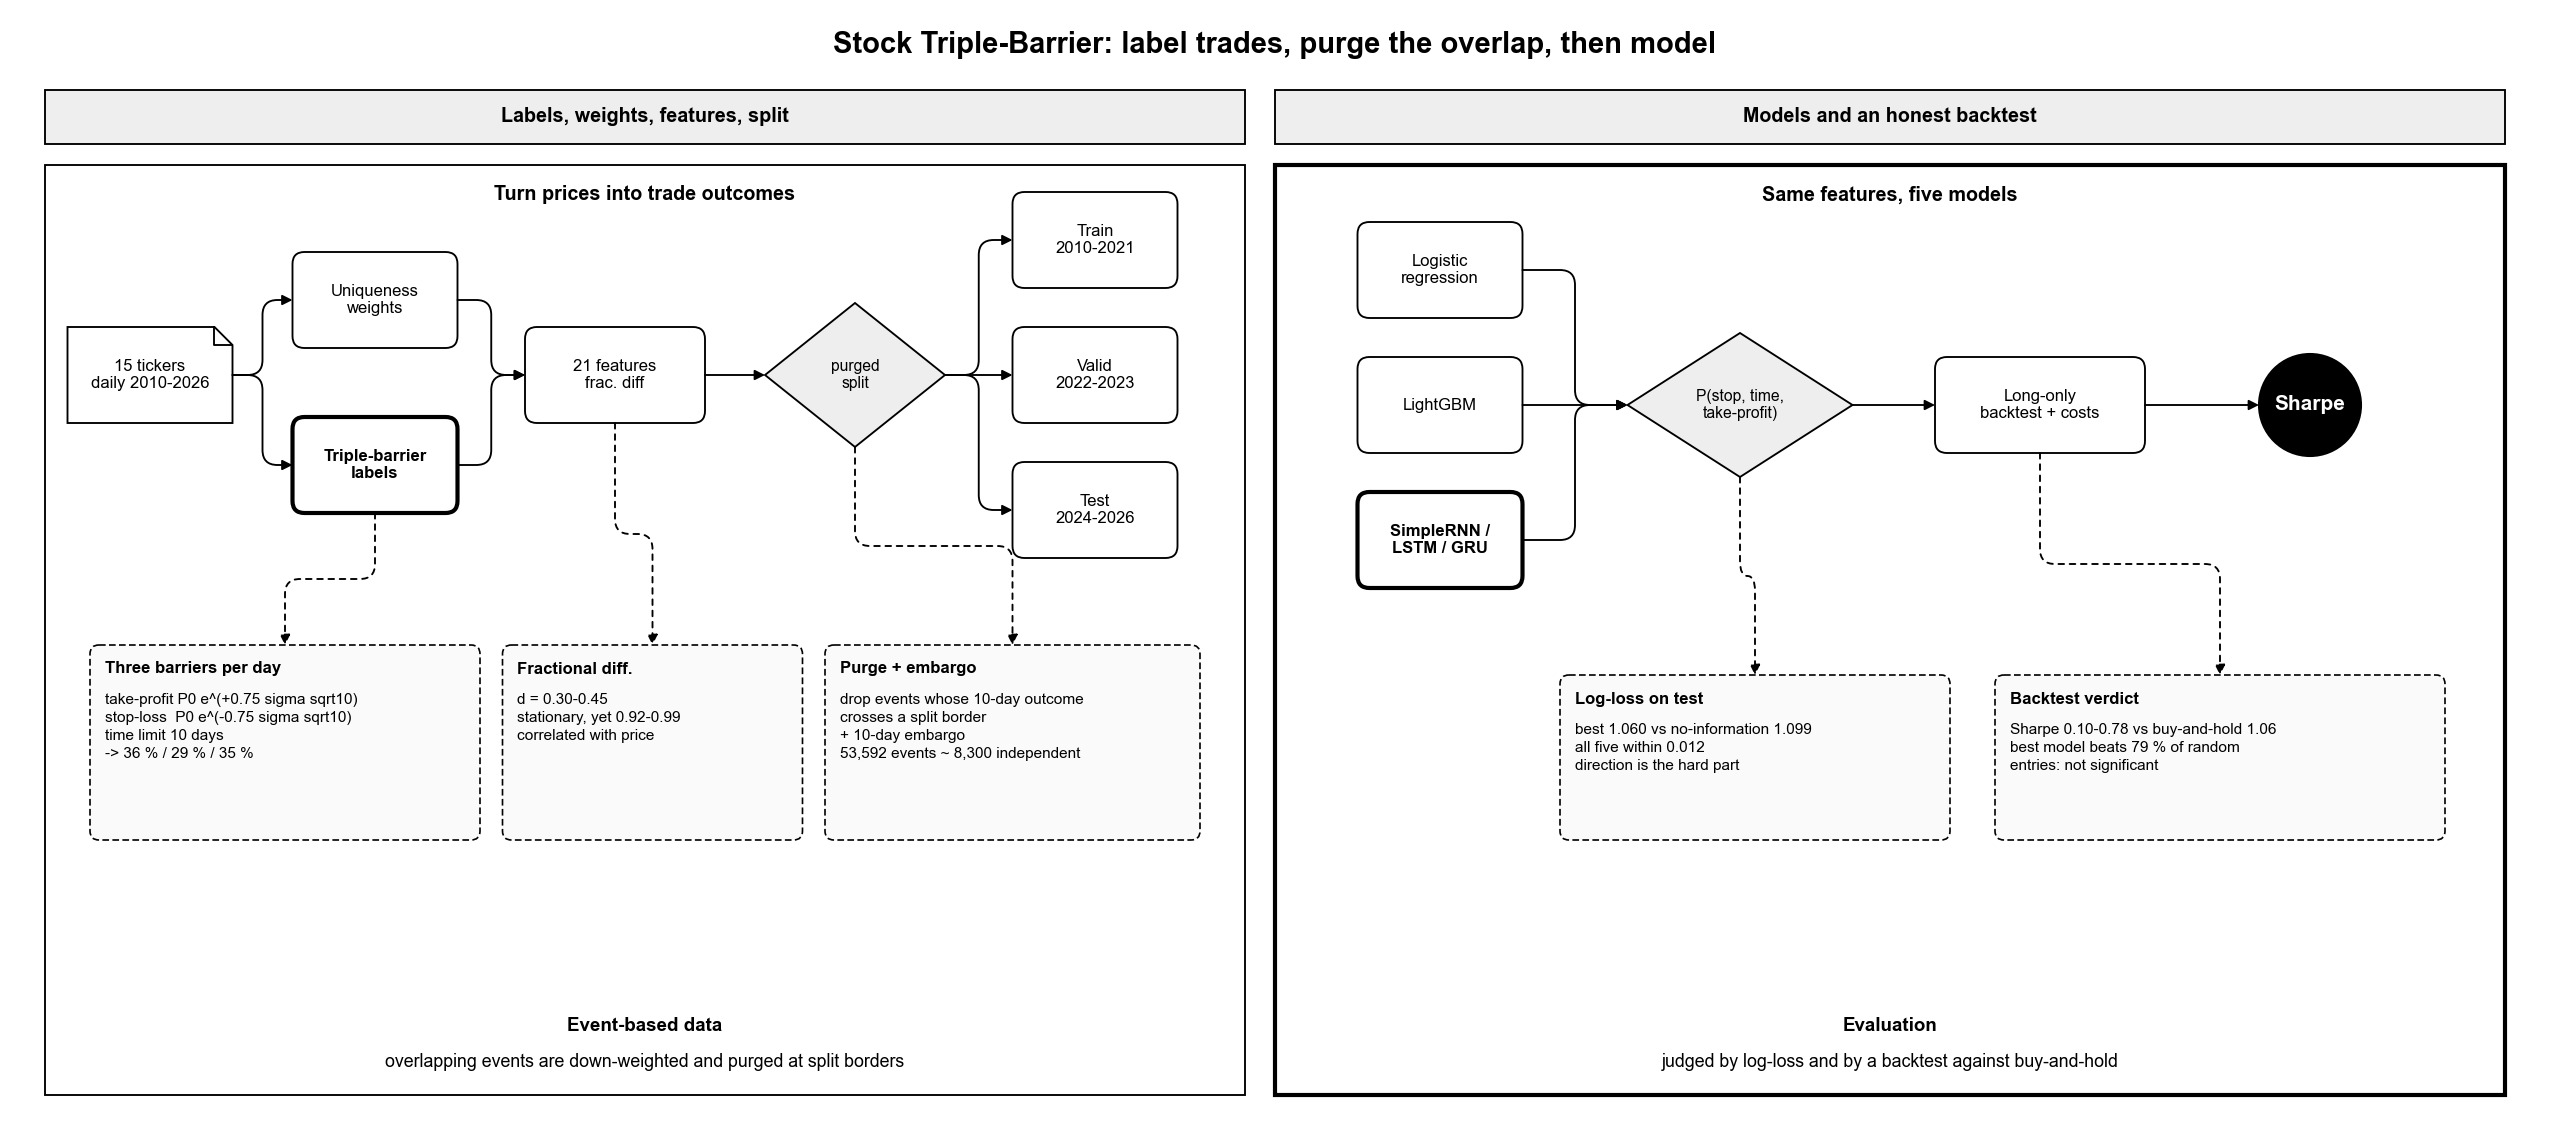

**Aim** → label every possible trade by what really happens to it (take-profit, stop-loss or time-out), then find out whether SimpleRNN / LSTM / GRU can predict that outcome better than guessing, and whether it makes money after costs, without letting the future leak in.

**Objectives**
1. Learn how daily prices behave (fat tails, stationarity, volatility) and why R² on prices fools you
2. Build triple-barrier labels, check them, and handle labels that overlap in time
3. Make stationary features that only use the past, and split by time with purging
4. Compare a no-information baseline, logistic regression, LightGBM, SimpleRNN, LSTM and GRU
5. Test once on 2024–2026 and backtest a simple trading rule against buy-and-hold and random entries

**Where it could help** → a sanity check before trusting any trading signal: label trades by outcome, remove overlapping samples, and compare with buy-and-hold and random entries.

# Setup

Settings, imports and the helper functions every part uses. Run once with Accelerator GPU T4 and Internet On.

In [ ]:
"""Optional · Settings → Accelerator GPU T4, Internet On (prices come from Yahoo Finance), then Run All.

[1/8] TICKERS: stocks that are labeled and modeled
    Default = 14 tech stocks
[2/8] MARKET: market context ticker
    Default = 'SPY'
[3/8] START / END: download period (END is exclusive, fixed for reproducible downloads)
    Default = '2010-01-01' / '2026-11-12'
[4/8] VOL_SPAN: EWM span in days of the daily volatility estimate
    Default = 20
[5/8] PT_MULT / SL_MULT: barrier width = mult × daily vol × sqrt(horizon)
    Default = 0.75 / 0.75
[6/8] HORIZON: vertical barrier in trading days
    Default = 10
[7/8] VALID_START / TEST_START: time split by event start date
    Default = '2022-01-01' / '2024-01-01'
[8/8] SAVE_FIGURES: also write every chart as a PNG into reports/figures
    Default = False
"""
from pathlib import Path

RANDOM_STATE  = 42
TICKERS       = ['NVDA', 'CRWD', 'AMD', 'ADBE', 'MSFT', 'GOOGL', 'INTC',
                 'AAPL', 'AMZN', 'CRM', 'IBM', 'TSLA', 'PYPL', 'XYZ']
MARKET        = 'SPY'
START         = '2010-01-01'
END           = '2026-11-12'
VOL_SPAN      = 20
PT_MULT       = 0.75
SL_MULT       = 0.75
HORIZON       = 10
VALID_START   = '2022-01-01'
TEST_START    = '2024-01-01'
SAVE_FIGURES  = False

CLASSES       = {-1: 'stop-loss', 0: 'time-out', 1: 'take-profit'}
ROOT          = Path('/kaggle/working')
RAW_DIR       = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
MODELS_DIR    = ROOT / 'models'
REPORTS_DIR   = ROOT / 'reports'
FIGURES_DIR   = REPORTS_DIR / 'figures'
LABEL_COLORS  = {-1: '#dc2626', 0: '#9ca3af', 1: '#15803d'}
PRICE_COLOR   = '#374151'

for folder in (RAW_DIR, PROCESSED_DIR, MODELS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

In [ ]:
%pip install -q yfinance==1.2.0
import os
os.environ['KERAS_BACKEND'] = 'torch'
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import balanced_accuracy_score, f1_score, log_loss
from statsmodels.tsa.stattools import adfuller

In [ ]:
RAW_FILE = RAW_DIR / "prices.parquet"


def download_prices(tickers=None, start=START, end=END, refresh=False) -> pd.DataFrame:
    """Long table: date, ticker, open, high, low, close, volume (split/dividend adjusted).

    Cached in data/raw/prices.parquet; set refresh=True to download again.
    """
    if RAW_FILE.exists() and not refresh:
        return pd.read_parquet(RAW_FILE)
    import yfinance as yf

    tickers = tickers or TICKERS + [MARKET]
    wide = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False, group_by="column")
    long = (wide.stack(level="Ticker", future_stack=True)
                .rename_axis(["date", "ticker"]).reset_index())
    long.columns = [c.lower() for c in long.columns]
    long = long.dropna(subset=["close"]).sort_values(["ticker", "date"]).reset_index(drop=True)
    long = long[["date", "ticker", "open", "high", "low", "close", "volume"]]
    long.to_parquet(RAW_FILE, index=False)
    return long


def save_processed(df: pd.DataFrame, name: str) -> None:
    df.to_parquet(PROCESSED_DIR / f"{name}.parquet", index=False)


def load_processed(name: str) -> pd.DataFrame:
    return pd.read_parquet(PROCESSED_DIR / f"{name}.parquet")

In [ ]:
LABELS = [-1, 0, 1]


def assign_split(df: pd.DataFrame, valid_start: str, test_start: str) -> pd.Series:
    """Split by event start date, then PURGE events whose label end t1 reaches into the next set
    (their outcome would overlap the next period's prices)."""
    vs, ts = pd.Timestamp(valid_start), pd.Timestamp(test_start)
    split = np.select([df["date"] < vs, df["date"] < ts], ["train", "valid"], "test")
    purge = ((split == "train") & (df["t1"] >= vs)) | ((split == "valid") & (df["t1"] >= ts))
    return pd.Series(np.where(purge, "purged", split), index=df.index)


class PurgedKFold:
    """K-fold over time-ordered events with purging and an embargo (Lopez de Prado, ch. 7).

    For each test fold [a, b]:
      - purge: drop training events whose interval [t0, t1] overlaps the test period
      - embargo: also drop training events starting within `embargo` days after the test period
    """

    def __init__(self, n_splits=5, embargo_days=5):
        self.n_splits, self.embargo = n_splits, pd.Timedelta(days=embargo_days)

    def split(self, t0: pd.Series, t1: pd.Series):
        dates = np.sort(t0.unique())
        for chunk in np.array_split(dates, self.n_splits):
            a, b = chunk[0], chunk[-1]
            test = (t0 >= a) & (t0 <= b)
            overlap = (t0 <= b) & (t1 >= a)
            embargo = (t0 > b) & (t0 <= b + self.embargo)
            train = ~test & ~overlap & ~embargo
            yield np.flatnonzero(train.to_numpy()), np.flatnonzero(test.to_numpy())


def make_sequences(df: pd.DataFrame, features: list, lookback: int):
    """For each event row, the window of the last `lookback` days of features of the same ticker
    (ending at the event day). Rows without a full window are dropped.
    Returns X (n, lookback, n_features) and the row index it belongs to."""
    X, idx = [], []
    for _, g in df.groupby("ticker", sort=False):
        values = g[features].to_numpy(dtype=np.float32)
        for j in range(lookback - 1, len(g)):
            X.append(values[j - lookback + 1: j + 1])
            idx.append(g.index[j])
    return np.stack(X), np.array(idx)


def score(y_true, proba, name="model", weights=None) -> dict:
    """proba columns ordered as LABELS (-1, 0, 1)."""
    pred = np.array(LABELS)[proba.argmax(1)]
    return {
        "model": name,
        "macro_f1": f1_score(y_true, pred, average="macro"),
        "balanced_acc": balanced_accuracy_score(y_true, pred),
        "log_loss": log_loss(y_true, proba, labels=LABELS, sample_weight=weights),
        "tp_precision": ((pred == 1) & (y_true == 1)).sum() / max((pred == 1).sum(), 1),
        "tp_recall": ((pred == 1) & (y_true == 1)).sum() / max((y_true == 1).sum(), 1),
    }


def backtest_long(events: pd.DataFrame, signal: pd.Series, prices: pd.DataFrame, cost_bps: float = 10.0):
    """Long-only, one position per ticker at a time.

    Enter at the close of the event day when `signal` is True and the ticker is flat; exit at the close
    of t1 (barrier touch or vertical barrier). `cost_bps` is charged on entry and on exit.
    Returns (daily portfolio returns, trades). Portfolio = equal weight across tickers, idle cash earns 0.
    """
    trades, daily = [], {}
    close = prices.pivot(index="date", columns="ticker", values="close")
    rets = np.log(close).diff()
    cost = cost_bps / 1e4
    for ticker, g in events[signal.reindex(events.index).fillna(False).to_numpy()].groupby("ticker"):
        held = pd.Series(0.0, index=close.index)
        busy_until = pd.Timestamp.min
        for _, e in g.sort_values("date").iterrows():
            if e["date"] <= busy_until:
                continue
            span = (close.index > e["date"]) & (close.index <= e["t1"])
            held[span] = rets.loc[span, ticker]
            first, last = np.flatnonzero(span)[[0, -1]]
            held.iloc[first] -= cost
            held.iloc[last] -= cost
            trades.append({"ticker": ticker, "entry": e["date"], "exit": e["t1"], "label": e["label"],
                           "ret": held[span].sum()})
            busy_until = e["t1"]
        daily[ticker] = held
    daily = pd.DataFrame(daily).reindex(columns=events["ticker"].unique()).fillna(0.0)
    return daily, pd.DataFrame(trades)


def performance(log_returns: pd.Series, periods: int = 252) -> dict:
    """CAGR, annualised volatility, Sharpe (rf = 0) and maximum drawdown of a daily log-return series."""
    r = log_returns.dropna()
    equity = np.exp(r.cumsum())
    years = len(r) / periods
    simple = np.exp(r) - 1
    return {
        "total_return": equity.iloc[-1] - 1,
        "cagr": equity.iloc[-1] ** (1 / years) - 1,
        "ann_vol": simple.std() * np.sqrt(periods),
        "sharpe": simple.mean() / simple.std() * np.sqrt(periods) if simple.std() > 0 else np.nan,
        "max_drawdown": (equity / equity.cummax() - 1).min(),
    }

In [ ]:
def ffd_weights(d: float, threshold: float = 1e-4, max_len: int = 500) -> np.ndarray:
    """Weights of the fixed-width window fractional difference (1 - B)^d.
    w_0 = 1, w_k = -w_{k-1} * (d - k + 1) / k ; stop when |w_k| < threshold."""
    w = [1.0]
    for k in range(1, max_len):
        w_k = -w[-1] * (d - k + 1) / k
        if abs(w_k) < threshold:
            break
        w.append(w_k)
    return np.array(w)


def frac_diff(series: pd.Series, d: float, threshold: float = 1e-3) -> pd.Series:
    """x~_t = sum_k w_k x_{t-k}  (NaN for the first len(w)-1 values)."""
    w = ffd_weights(d, threshold)
    x = series.to_numpy(dtype=float)
    out = np.full(len(x), np.nan)
    if len(x) >= len(w):
        out[len(w) - 1:] = np.convolve(x, w, mode="valid")
    return pd.Series(out, index=series.index)


def min_d_stationary(log_price: pd.Series, d_grid=np.arange(0, 1.01, 0.05), alpha=0.05, threshold=1e-3):
    """Smallest d whose fractionally differenced series passes the ADF test (keeps the most memory).
    Returns (d, table of ADF p-value and correlation with the original series per d)."""
    rows = []
    for d in d_grid:
        fd = frac_diff(log_price, d, threshold).dropna()
        p = adfuller(fd, maxlag=1, regression="c", autolag=None)[1]
        corr = np.corrcoef(log_price.loc[fd.index], fd)[0, 1]
        rows.append({"d": round(d, 2), "adf_p": p, "corr_with_price": corr})
    table = pd.DataFrame(rows)
    ok = table[table.adf_p < alpha]
    return (float(ok.d.iloc[0]) if len(ok) else 1.0), table


def rsi(close: pd.Series, n: int = 14) -> pd.Series:
    """Relative Strength Index (Wilder): 100 - 100 / (1 + avg_gain / avg_loss)."""
    delta = close.diff()
    gain = delta.clip(lower=0).ewm(alpha=1 / n, min_periods=n).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / n, min_periods=n).mean()
    return 100 - 100 / (1 + gain / loss)


def ticker_features(g: pd.DataFrame, market: pd.DataFrame, d: float) -> pd.DataFrame:
    """Feature table for ONE ticker. `g` and `market` have columns open/high/low/close/volume, date index."""
    c, h, l, v = g["close"], g["high"], g["low"], g["volume"]
    r = np.log(c).diff()
    f = pd.DataFrame(index=g.index)
    for k in (1, 5, 10, 21):
        f[f"ret_{k}"] = np.log(c / c.shift(k))
    f["vol_21"] = r.rolling(21).std()
    f["vol_ratio_5_21"] = r.rolling(5).std() / f["vol_21"]
    f["rsi_14"] = rsi(c, 14) / 100
    ema12, ema26 = c.ewm(span=12, adjust=False).mean(), c.ewm(span=26, adjust=False).mean()
    macd = ema12 - ema26
    f["macd_hist"] = (macd - macd.ewm(span=9, adjust=False).mean()) / c
    sma20, std20 = c.rolling(20).mean(), c.rolling(20).std()
    f["bb_pctb"] = (c - (sma20 - 2 * std20)) / (4 * std20)
    f["bb_width"] = 4 * std20 / sma20
    f["dist_sma_50"] = c / c.rolling(50).mean() - 1
    f["dist_sma_200"] = c / c.rolling(200).mean() - 1
    f["dist_ema_21"] = c / c.ewm(span=21, adjust=False).mean() - 1
    tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(axis=1)
    f["atr_14"] = tr.ewm(alpha=1 / 14, min_periods=14).mean() / c
    logv = np.log1p(v)
    f["volume_z"] = (logv - logv.rolling(21).mean()) / logv.rolling(21).std()
    f["ffd_close"] = frac_diff(np.log(c), d)
    mc = market["close"].reindex(g.index)
    mr = np.log(mc).diff()
    f["mkt_ret_1"] = mr
    f["mkt_ret_5"] = np.log(mc / mc.shift(5))
    f["mkt_vol_21"] = mr.rolling(21).std()
    f["rel_strength_21"] = f["ret_21"] - np.log(mc / mc.shift(21))
    f["beta_63"] = r.rolling(63).cov(mr) / mr.rolling(63).var()
    return f.replace([np.inf, -np.inf], np.nan)


FEATURES = ["ret_1", "ret_5", "ret_10", "ret_21", "vol_21", "vol_ratio_5_21", "rsi_14", "macd_hist",
            "bb_pctb", "bb_width", "dist_sma_50", "dist_sma_200", "dist_ema_21", "atr_14", "volume_z",
            "ffd_close", "mkt_ret_1", "mkt_ret_5", "mkt_vol_21", "rel_strength_21", "beta_63"]

In [ ]:
def daily_volatility(close: pd.Series, span: int = 20) -> pd.Series:
    """EWM standard deviation of daily log returns (uses data up to and including t)."""
    return np.log(close).diff().ewm(span=span, min_periods=span).std()


def triple_barrier(close: pd.Series, vol: pd.Series, horizon: int = 10,
                   pt_mult: float = 2.0, sl_mult: float = 2.0) -> pd.DataFrame:
    """Label every day of ONE ticker. Returns a DataFrame indexed like `close` with:
    label (-1/0/1), t1 (date the label is known = touch date or vertical barrier),
    days_held, ret (log return from t0 to t1), barrier (width in log-return units)."""
    logp = np.log(close.to_numpy())
    v = vol.to_numpy()
    dates = close.index
    n = len(close)
    label = np.full(n, np.nan)
    t1_idx = np.full(n, -1)
    ret = np.full(n, np.nan)
    width = v * np.sqrt(horizon)
    for i in range(n - horizon):
        if np.isnan(width[i]):
            continue
        path = logp[i + 1: i + 1 + horizon] - logp[i]
        up = np.flatnonzero(path >= pt_mult * width[i])
        dn = np.flatnonzero(path <= -sl_mult * width[i])
        first_up = up[0] if len(up) else horizon
        first_dn = dn[0] if len(dn) else horizon
        if first_up < first_dn:
            label[i], k = 1, first_up
        elif first_dn < first_up:
            label[i], k = -1, first_dn
        else:
            label[i], k = 0, horizon - 1
        t1_idx[i] = i + 1 + k
        ret[i] = path[k]
    out = pd.DataFrame({"label": label, "ret": ret, "barrier": width}, index=dates)
    valid = t1_idx >= 0
    out["t1"] = pd.NaT
    out.loc[valid, "t1"] = dates[t1_idx[valid]]
    out["days_held"] = np.where(valid, t1_idx - np.arange(n), np.nan)
    return out


def average_uniqueness(t0: pd.Index, t1: pd.Series, all_dates: pd.Index) -> pd.Series:
    """Average uniqueness of each event (one ticker).

    Concurrency c_t = number of events whose holding interval (t0, t1] contains day t.
    Uniqueness of event i = mean over its interval of 1 / c_t  (1 = no overlap, 1/H = fully overlapped).
    """
    pos = pd.Series(np.arange(len(all_dates)), index=all_dates)
    start = pos.reindex(t0).to_numpy() + 1
    end = pos.reindex(t1).to_numpy()
    conc = np.zeros(len(all_dates) + 1)
    np.add.at(conc, start, 1)
    np.add.at(conc, end + 1, -1)
    conc = np.cumsum(conc)[:-1]
    inv = np.where(conc > 0, 1 / np.maximum(conc, 1), 0)
    csum = np.concatenate([[0], np.cumsum(inv)])
    u = (csum[end + 1] - csum[start]) / (end - start + 1)
    return pd.Series(u, index=t0)


def cusum_filter(close: pd.Series, threshold: pd.Series | float) -> pd.DatetimeIndex:
    """Symmetric CUSUM filter on log returns: emit an event when the cumulative up- or down-move
    since the last event exceeds `threshold` (a number or a per-day Series)."""
    r = np.log(close).diff().dropna()
    h = threshold.reindex(r.index) if isinstance(threshold, pd.Series) else pd.Series(threshold, index=r.index)
    events, s_pos, s_neg = [], 0.0, 0.0
    for t, x in r.items():
        if np.isnan(h[t]):
            continue
        s_pos, s_neg = max(0.0, s_pos + x), min(0.0, s_neg + x)
        if s_pos > h[t]:
            s_pos = 0.0
            events.append(t)
        elif s_neg < -h[t]:
            s_neg = 0.0
            events.append(t)
    return pd.DatetimeIndex(events)


def label_all(prices: pd.DataFrame, vol_span=20, horizon=10, pt_mult=2.0, sl_mult=2.0) -> pd.DataFrame:
    """Triple-barrier labels + uniqueness for every ticker in a long price table."""
    parts = []
    for ticker, g in prices.groupby("ticker", sort=True):
        close = g.set_index("date")["close"]
        vol = daily_volatility(close, vol_span)
        lab = triple_barrier(close, vol, horizon, pt_mult, sl_mult)
        lab["vol"] = vol
        lab = lab.dropna(subset=["label"])
        lab["uniqueness"] = average_uniqueness(lab.index, lab["t1"], close.index).to_numpy()
        lab["ticker"] = ticker
        parts.append(lab.rename_axis("date").reset_index())
    out = pd.concat(parts, ignore_index=True)
    out["label"] = out["label"].astype(int)
    return out

In [ ]:
CMAP = "Greys"


def set_style():
    """Grey 'darkgrid' look (same as my Ensemble / Tuberculosis notebooks)."""
    sns.set_style("darkgrid")
    sns.set_palette("gray", 8)
    sns.set_context("notebook", font_scale=1.05)
    plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})


def savefig(fig, name):
    """Write the chart to FIGURES_DIR/<name>.png when SAVE_FIGURES is on."""
    if SAVE_FIGURES:
        fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=110)

# Part [1/5] Data Understanding

Before predicting anything, I want to know how daily prices behave, and why my first version's R² ≈ 0.99 was misleading.

**Data** → daily OHLCV (open, high, low, close, volume) from Yahoo Finance via `yfinance`, split and dividend adjusted, 2010-01-01 to 2026-11-11, for the 14 stocks of my first version plus `SPY` (S&P 500 ETF) as market context.

**Outlines**
1. Download prices
2. Data health
3. Prices over time
4. Returns: distribution and fat tails
5. Stationarity: price vs return
6. Autocorrelation and volatility clustering
7. The price-level trap
    - 7.1 Naive "tomorrow = today" forecast
    - 7.2 Scaling before splitting
8. Summary & decisions

In [ ]:
from scipy import stats
from sklearn.metrics import r2_score
from sklearn.preprocessing import MinMaxScaler
from statsmodels.graphics.tsaplots import plot_acf

EXAMPLE = "AAPL"
ACF_LAGS = 40
TEST_SHARE = 0.2
ALPHA = 0.05

set_style()

# [1/8] Download prices

**Aim** → download adjusted daily prices once and cache them in `data/raw/prices.parquet`.

`END` is fixed, so re-running gives the same data (Yahoo can still revise adjusted prices after new splits or dividends).

In [ ]:
prices = download_prices()
close = prices.pivot(index="date", columns="ticker", values="close")

In [ ]:
print(f"{len(prices):,} rows | {prices.ticker.nunique()} tickers | {prices.date.min().date()} to {prices.date.max().date()}")
prices.head()

# [2/8] Data health

**What I'm trying to do** → look for missing days, gaps or impossible values before I trust the data.

In [ ]:
health = prices.groupby("ticker").agg(
    first_day=("date", "min"), last_day=("date", "max"), trading_days=("date", "size"),
    missing_close=("close", lambda s: s.isna().sum()),
    zero_volume_days=("volume", lambda s: (s == 0).sum()),
    non_positive_price=("close", lambda s: (s <= 0).sum()),
)
largest_moves = (np.log(close).diff().abs().max().sort_values(ascending=False) * 100)

In [ ]:
health

In [ ]:
largest_moves.round(1).rename("largest |daily log return| %").head(6)

**Answer:** clean. No missing closes, no zero or negative prices, one day with zero volume.
- Four stocks start later because they listed later: `TSLA` (2010-06), `PYPL` (2015-07), `XYZ` (2015-11, ticker `SQ` until 2025) and `CRWD` (2019-06)
- The biggest daily moves (up to about 40 %) are real earnings or market shocks, not errors → nothing is removed

# [3/8] Prices over time

**What I'm trying to do** → put all stocks on one scale (growth of \$1 from each stock's first day) and see who won.

In [ ]:
growth = close.apply(lambda s: s / s.dropna().iloc[0])
final_growth = growth.ffill().iloc[-1].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, 6))
for t in growth.columns:
    lw, c = (2.2, "#dc2626") if t == MARKET else (1, None)
    ax.plot(growth.index, growth[t], lw=lw, color=c, label=t)
ax.set(yscale="log", ylabel="growth of $1 (log scale)", title="Growth of $1 since each stock's first day")
ax.legend(ncol=5, fontsize=8, loc="upper left")
savefig(fig, "01_growth")
plt.close(fig)

In [ ]:
final_growth.round(1).rename("growth of $1")

In [ ]:
fig

**Answer:** a huge spread: ×411 (`NVDA`) and ×245 (`TSLA`) down to ×1.6 (`PYPL`). The market (`SPY`) grew ×9.

(!) I picked these stocks **today**, and most of them are famous winners. That's **survivorship / selection bias** (choosing with hindsight), and it makes any buy-only strategy look good. So in Part 5 I compare against buy-and-hold of the **same** stocks and against random entries.

# [4/8] Returns: distribution and fat tails

**What I'm trying to do** → check whether daily returns follow a normal bell curve, or have more extreme days than that.

**Log return in one line** → how much the price changed since yesterday, written so that daily changes can simply be added up.

$$r_t = \ln\frac{P_t}{P_{t-1}}$$
- $P_t$ → closing price today, $P_{t-1}$ → yesterday
- $r_t$ → **log return**: about the same as the % change for small moves
- In short → today's price change in %, in a form where 10 daily returns add up to the 10-day return. 100 → 102 is about +2 %

**Fat tails in one line** → extreme days happen much more often than a bell curve says.

$$\text{excess kurtosis} = \frac{1}{n}\sum_t\left(\frac{r_t - \bar{r}}{s}\right)^4 - 3$$
- $\bar r$ → average return, $s$ → standard deviation (typical size of a daily move)
- 4th power → big days count a lot more than normal days
- $-3$ → makes a normal bell curve score exactly 0
- In short → above 0 = more crazy days than a bell curve expects

$$JB = \frac{n}{6}\left(S^2 + \frac{K^2}{4}\right)$$
- $JB$ → **Jarque-Bera test**: checks whether the shape is normal
- $S$ → skew (lopsided to one side), $K$ → excess kurtosis, $n$ → number of days
- $H_0$ → returns are normal; a tiny p-value says they are not
- In short → JB gets big when the curve is lopsided or has fat tails: big JB → tiny p → "not normal"

The real histogram and Q-Q plot come after the next cell.

In [ ]:
returns = np.log(close).diff()
moments = pd.DataFrame({
    "mean_daily_%": returns.mean() * 100,
    "std_daily_%": returns.std() * 100,
    "skew": returns.skew(),
    "excess_kurtosis": returns.kurt(),
    "jarque_bera_p": returns.apply(lambda s: stats.jarque_bera(s.dropna()).pvalue),
}).sort_values("std_daily_%", ascending=False)

r = returns[EXAMPLE].dropna()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.histplot(r, bins=150, stat="density", color=PRICE_COLOR, ax=axes[0], label="observed")
x = np.linspace(r.min(), r.max(), 400)
axes[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), color="#dc2626", lw=2, label="normal, same mean & std")
axes[0].set(xlim=(-0.1, 0.1), title=f"{EXAMPLE} daily log returns", xlabel="log return")
axes[0].legend()
stats.probplot(r, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(color=PRICE_COLOR, markersize=3)
axes[1].get_lines()[1].set(color="#dc2626")
axes[1].set_title(f"{EXAMPLE} Q-Q plot vs normal")
savefig(fig, "01_returns_distribution")
plt.close(fig)

In [ ]:
moments.round(3)

In [ ]:
fig

**Answer:** no. Every stock has fat tails (positive excess kurtosis) and Jarque-Bera rejects normality with p ≈ 0. The Q-Q plot bends away at both ends.

→ Barriers should scale with each stock's **own volatility**: a fixed % threshold means very different things for `IBM` (≈ 1.6 % daily std) and `TSLA` (≈ 3.6 %).

# [5/8] Stationarity: price vs return

**What I'm trying to do** → check whether prices and returns keep a stable average and spread over time.

**Stationary in one line** → a series is stationary when its average and spread stay about the same over time, so what a model learns from the past still fits the future.

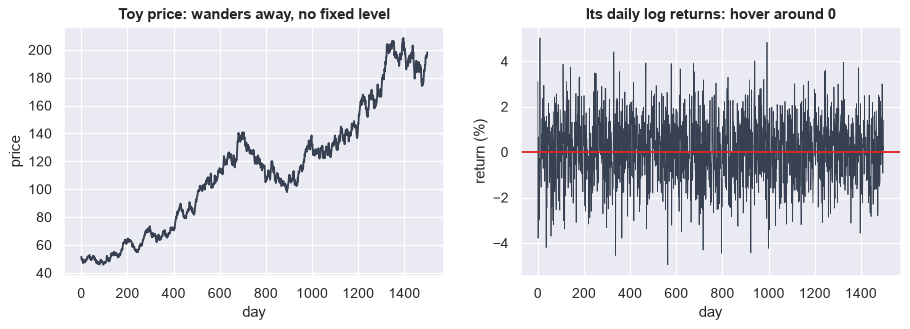

The picture is a toy random walk: the price wanders off with no home level, while its returns keep hovering around 0.

**How the ADF test checks it**
1. Take today's change $\Delta y_t$
2. Check whether it depends on yesterday's level $y_{t-1}$: if a high level tends to be followed by a fall, the series gets pulled back home → stationary
3. If the level has no pull ($\gamma = 0$), the series can wander anywhere → non-stationary (a "unit root")

$$\Delta y_t = \alpha + \gamma\, y_{t-1} + \sum_{i} \beta_i\, \Delta y_{t-i} + \varepsilon_t$$
- $\Delta y_t$ → today's change, $y_{t-1}$ → yesterday's level
- $\gamma$ → pull back towards a home level (step 2); $\gamma = 0$ → no pull
- $\beta_i\, \Delta y_{t-i}$ → recent changes, so short-term patterns don't fool the test
- $\alpha$ → constant, $\varepsilon_t$ → noise
- $H_0$: $\gamma = 0$ (non-stationary). p < 0.05 → stationary
- In short → does the series get pulled back to a usual level? Yes → stationary. No → it wanders off, like a price

In [ ]:
adf = pd.DataFrame({
    "adf_p_log_price": np.log(close).apply(lambda s: adfuller(s.dropna(), maxlag=1, autolag=None)[1]),
    "adf_p_log_return": returns.apply(lambda s: adfuller(s.dropna(), maxlag=1, autolag=None)[1]),
})
adf["price_stationary"] = adf["adf_p_log_price"] < ALPHA
adf["return_stationary"] = adf["adf_p_log_return"] < ALPHA

In [ ]:
adf.round(4)

**Answer:**
- Log prices are **non-stationary** for every stock (ADF p between 0.31 and 0.99, unit root not rejected)
- Returns are stationary for all of them (p ≈ 0)

A model trained on price levels learns "the price is near where it was", which doesn't carry over to new price ranges. → My features are built from **returns and ratios**, plus a *fractionally* differenced price that keeps some memory while being stationary (Part 3).

# [6/8] Autocorrelation and volatility clustering

**What I'm trying to do** → see whether past returns predict future returns, and whether past volatility predicts future volatility.

**Autocorrelation in one line** → how much today looks like $k$ days ago: +1 = the same, 0 = no link, −1 = the opposite.

$$\rho_k = \frac{\sum_t (r_t - \bar r)(r_{t-k} - \bar r)}{\sum_t (r_t - \bar r)^2}$$
- $\rho_k$ → **autocorrelation at lag $k$** (lag = how many days back)
- top → do today and $k$ days ago tend to be above / below average together?
- bottom → scales the result to between −1 and +1
- shaded band in the plot → the 95 % range that pure chance gives
- In short → a bar sticking out of the band means the past says something about today

The real plots come after the next cell.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
plot_acf(r, lags=ACF_LAGS, ax=axes[0], color=PRICE_COLOR, vlines_kwargs={"colors": PRICE_COLOR})
axes[0].set(title=f"{EXAMPLE}: ACF of returns", ylim=(-0.15, 0.3))
plot_acf(r ** 2, lags=ACF_LAGS, ax=axes[1], color="#dc2626", vlines_kwargs={"colors": "#dc2626"})
axes[1].set(title=f"{EXAMPLE}: ACF of squared returns (volatility)", ylim=(-0.15, 0.3))
savefig(fig, "01_acf")
plt.close(fig)

acf_summary = pd.DataFrame({
    "acf1_returns": returns.apply(lambda s: s.autocorr(1)),
    "acf1_squared_returns": (returns ** 2).apply(lambda s: s.autocorr(1)),
})

In [ ]:
acf_summary.round(3)

In [ ]:
fig

**Answer:**
- Returns: almost **no** autocorrelation (lag-1 between −0.10 and 0.05) → tomorrow's direction is very hard to guess from past returns alone
- Squared returns (size of the move, ignoring direction): positive for every stock (0.04 for `IBM` up to 0.40 for `SPY`) → **volatility clusters**: calm and turbulent periods last a while

→ Volatility can be predicted, so barriers based on recent volatility make sense. Direction is the hard part.

# [7/8] The price-level trap
## 7.1 Naive "tomorrow = today" forecast

**Aim** → show why R² ≈ 0.99 on prices is not skill, using a forecast that needs no model at all.

**Question:** how good is R² ≈ 0.99 on scaled prices, really?

**R² in one line** → how much of the ups and downs the forecast explains: 1 = all of it, 0 = no better than the average.

$$R^2 = 1 - \frac{\sum (y_t - \hat y_t)^2}{\sum (y_t - \bar y)^2}$$
- $y_t$ → real value, $\hat y_t$ → forecast, $\bar y$ → average of all real values
- top → forecast errors, bottom → how far the values spread around their average
- naive forecast → $\hat P_t = P_{t-1}$: tomorrow = today
- In short → R² compares the errors with the total spread. A price that climbs from 50 to 200 has a huge spread, while one day's error is tiny, so R² lands near 1 with zero skill

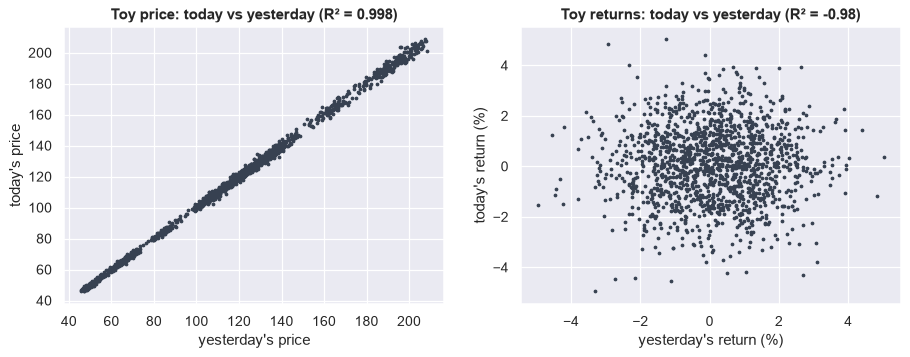

The picture uses a toy random walk: on prices, "today vs yesterday" is almost a straight line; on returns it's a shapeless cloud.

In [ ]:
naive = pd.DataFrame({
    "r2_price_naive": close.apply(lambda s: r2_score(s.dropna()[1:], s.dropna().shift(1)[1:])),
    "r2_return_naive": returns.apply(lambda s: r2_score(s.dropna()[1:], s.dropna().shift(1)[1:])),
})

In [ ]:
naive.round(4)

**Answer:** copying yesterday's price gives **R² between 0.995 and 0.9996** on price levels without learning anything, because a trending price spreads a lot compared with one day's change. On **returns** the same trick scores about −1.

→ My first version's R² ≈ 0.99 mostly measured this effect. R² on prices is not proof of forecasting skill.

## 7.2 Scaling before splitting

**Question:** what goes wrong when `MinMaxScaler` is fitted on the full series before the train/test split (as in my first version)?

**Min-max scaling in one line** → squeeze values into 0 to 1, using the smallest and biggest value the scaler has seen.

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$
- $x_{min}$, $x_{max}$ → smallest and biggest value **in the data the scaler was fitted on**
- $x'$ → scaled value: 0 at the old minimum, 1 at the old maximum
- In short → if the scaler sees the test period, it already knows the highest future price. Fitted on train only, a new high shows up above 1, which is the honest picture

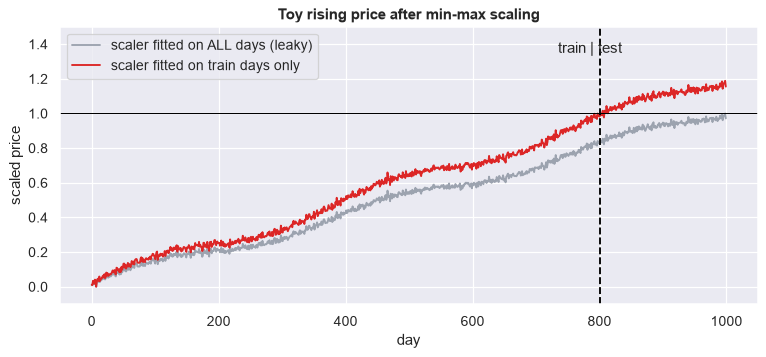

Toy rising price: with the leaky scaler the test part never goes above 1; with the train-only scaler it does.

In [ ]:
s = close[EXAMPLE].dropna()
split = int(len(s) * (1 - TEST_SHARE))
leaky = MinMaxScaler().fit(s.to_frame())
honest = MinMaxScaler().fit(s.iloc[:split].to_frame())
scaled_test = pd.DataFrame({
    "leaky_scaler": leaky.transform(s.iloc[split:].to_frame()).ravel(),
    "train_only_scaler": honest.transform(s.iloc[split:].to_frame()).ravel(),
})

In [ ]:
scaled_test.describe().loc[["min", "max"]].round(2)

**Answer:** the leaky scaler keeps test prices inside [0, 1] (0.45 to 1.00), because it already saw the test period's maximum. Fitted on training data only, test values reach 1.96: prices the model has never seen. The leaky version quietly tells the model the future price range.

→ Every scaler in this notebook is fitted on the **training period only**.

# [8/8] Summary & decisions

**Aim** → turn each finding into a decision for the next parts.

| Finding | Decision |
|---|---|
| Clean data; four stocks listed later | keep all; each stock contributes from its first day |
| Universe picked in hindsight (survivorship bias) | compare strategies with buy-and-hold of the same stocks and random entries |
| Fat tails, very different volatility per stock | barriers scaled by each stock's own recent volatility |
| Prices non-stationary, returns stationary | features from returns / ratios + fractionally differenced price |
| Returns barely autocorrelated, volatility clusters | volatility-based barriers; expect modest directional skill |
| R² on prices is ≈ 0.999 for a naive forecast | predict **triple-barrier outcomes** instead of price levels |
| Scaler fitted before splitting leaks the future | fit every transformation on the training period only |

# Part [2/5] Triple-Barrier Labeling

Here I swap "predict tomorrow's price" for the trader's question: *if I buy today, do I hit my profit target, my stop-loss, or run out of time first?* A fixed-horizon label ("is the price higher in 10 days?") ignores the path: a trade that falls 15 % and then recovers gets the same label as one that rose steadily. Triple-barrier labels follow the path, like a real stop-loss order.

Method from Marcos López de Prado, *Advances in Financial Machine Learning* (2018), chapters 2–4.

**Outlines**
1. Load prices
2. The triple-barrier method
3. Daily volatility: the barrier ruler
4. Three example trades
5. Label every stock
    - 5.1 Brute-force check
    - 5.2 Label distribution
6. Sensitivity to the settings
7. Triple-barrier vs fixed-horizon labels
8. Overlapping labels and sample uniqueness
9. CUSUM filter: sampling events instead of every day
10. Summary

In [ ]:
EXAMPLE = "AAPL"
MULT_GRID = [0.5, 0.75, 1.0, 1.5]
HORIZON_GRID = [5, 10, 20]
N_CHECK = 300
CHECK_SEED = 7
CUSUM_VOL_MULT = 1.0

set_style()

# [1/10] Load prices

**Aim** → load the cached prices from Part 1 (the 14 stocks; `SPY` is only used as a feature later).

In [ ]:
prices = download_prices()
stocks = prices[prices.ticker.isin(TICKERS)].copy()
close = stocks.pivot(index="date", columns="ticker", values="close")

In [ ]:
print(f"{stocks.ticker.nunique()} stocks, {len(stocks):,} stock-days")

# [2/10] The triple-barrier method

**Aim** → give every day a label that says what would have happened to a trade bought that day.

**Triple-barrier in one line** → buy today, draw a profit line above, a loss line below and a time limit to the right; whichever the price touches first is the label.

**How it works**
1. **Event** → a possible trade on day $t_0$ at closing price $P_0$
2. **Ruler** → today's daily volatility $\sigma_{t_0}$, the typical size of one day's move (see [3/10])
3. **Three barriers** → upper (take-profit) and lower (stop-loss) at the same distance from $P_0$, and a vertical one $H$ = 10 trading days later
4. **Walk forward day by day** → the first barrier the closing price touches decides the label
5. **Write down $t_1$** → the day the label became known (at most $t_0 + H$); I need it later for splitting and for overlaps

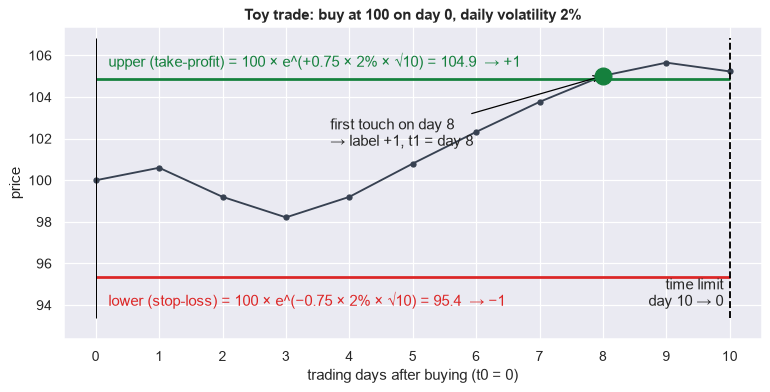

The picture is a toy trade; [4/10] shows three real `AAPL` trades.

| Barrier | Level | Label if touched first |
|---|---|---|
| upper (take-profit) | $P_0 \cdot e^{+m \,\sigma_{t_0} \sqrt{H}}$ | $+1$ |
| lower (stop-loss) | $P_0 \cdot e^{-m \,\sigma_{t_0} \sqrt{H}}$ | $-1$ |
| vertical (time limit) | $t_0 + H$ trading days | $0$ |

- $m$ → barrier multiplier (`PT_MULT` = `SL_MULT` = 0.75)
- $H$ → horizon (`HORIZON` = 10 days)
- $\sigma\sqrt{H}$ → typical size of an $H$-day move (volatility grows with the square root of time)
- In short → both barriers sit 0.75 "typical 10-day moves" away from the buy price, so they mean the same thing for a calm stock and a wild one

# [3/10] Daily volatility: the barrier ruler

**Aim** → measure how big a normal daily move is right now, for each stock, using only the past.

**EWM volatility in one line** → the typical size of a daily return, where recent days count more than old ones.

**How it works**
1. Take the daily log returns up to today
2. Give each past day a weight that shrinks the further back it is (span 20 → today gets about 9.5 %, a month ago much less)
3. The weighted standard deviation of those returns = today's volatility $\sigma_t$

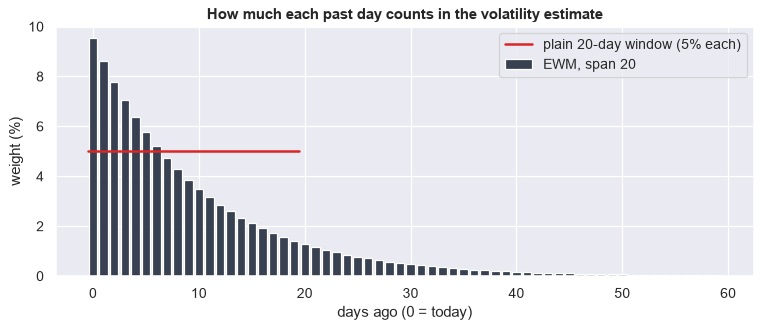

$$\sigma_t = \sqrt{\text{EWMA}_{\text{span}=20}\left[(r_t - \bar r_t)^2\right]}$$
- $r_t - \bar r_t$ → how far a day's return is from the recent average
- $\text{EWMA}_{\text{span}=20}$ → **exponentially weighted moving average**: the shrinking weights from step 2
- In short → today's volatility = the size of recent daily moves, with last week counting more than last month, and nothing from the future

In [ ]:
vol = close.apply(lambda s: daily_volatility(s.dropna(), VOL_SPAN))
vol_summary = (vol * 100).describe().T[["mean", "min", "50%", "max"]].rename(columns={"50%": "median"})

fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
axes[0].plot(close.index, close[EXAMPLE], color=PRICE_COLOR)
axes[0].set(yscale="log", title=f"{EXAMPLE} close (log scale)")
axes[1].plot(vol.index, vol[EXAMPLE] * 100, color="#dc2626")
axes[1].set(ylabel="daily volatility (%)", title=f"{EXAMPLE} EWM daily volatility (span {VOL_SPAN})")
savefig(fig, "02_volatility")
plt.close(fig)

In [ ]:
vol_summary.round(2)

In [ ]:
fig

**Answer:** volatility moves a lot over time (spikes in 2020 and during sell-offs) and differs between stocks → the barriers are wide in turbulent periods and narrow in calm ones.

# [4/10] Three example trades

**What I'm trying to do** → see the barriers on real price paths, one trade for each label.

In [ ]:
c_ex, v_ex = close[EXAMPLE].dropna(), vol[EXAMPLE].dropna()
lab_ex = triple_barrier(c_ex, v_ex.reindex(c_ex.index), HORIZON, PT_MULT, SL_MULT).dropna(subset=["label"])
examples = {k: lab_ex[(lab_ex.label == k) & (lab_ex.index.year == 2023)].index[5] for k in (1, -1, 0)}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, (k, t0) in zip(axes, examples.items()):
    i = c_ex.index.get_loc(t0)
    window = c_ex.iloc[i - 5: i + HORIZON + 4]
    w = lab_ex.loc[t0, "barrier"]
    p0 = c_ex.iloc[i]
    ax.plot(window.index, window.values, color=PRICE_COLOR, marker="o", ms=3)
    ax.hlines([p0 * np.exp(PT_MULT * w), p0 * np.exp(-SL_MULT * w)], t0, c_ex.index[i + HORIZON],
              colors=[LABEL_COLORS[1], LABEL_COLORS[-1]], lw=2)
    ax.axvline(c_ex.index[i + HORIZON], color="black", ls="--", lw=1)
    ax.axvline(t0, color="black", lw=0.8)
    ax.scatter([lab_ex.loc[t0, "t1"]], [c_ex.loc[lab_ex.loc[t0, "t1"]]], s=120, color=LABEL_COLORS[k], zorder=5)
    ax.set_title(f"{CLASSES[k]} (label {k:+d}) — start {t0.date()}")
    ax.tick_params(axis="x", rotation=30)
savefig(fig, "02_examples")
plt.close(fig)

In [ ]:
lab_ex.loc[list(examples.values()), ["label", "ret", "barrier", "t1", "days_held"]].round(4)

In [ ]:
fig

**What to look for** → green and red lines are the take-profit and stop-loss barriers, the dashed line is the time limit, and the big dot marks where the label was decided ($t_1$).

# [5/10] Label every stock

**Aim** → label every stock-day, except the last $H$ days of data, whose future isn't complete yet.

In [ ]:
labels = label_all(stocks, VOL_SPAN, HORIZON, PT_MULT, SL_MULT)

In [ ]:
print(f"{len(labels):,} labelled events")
labels.head()

## 5.1 Brute-force check

**Question:** does the fast labelling code give the same answer as a slow, obviously-correct loop?

I pick 300 random events, walk forward day by day by hand, and count how often the two answers differ.

In [ ]:
rng = np.random.default_rng(CHECK_SEED)
mismatches = 0
for k in rng.choice(len(labels), N_CHECK, replace=False):
    e = labels.iloc[k]
    c = close[e.ticker].dropna()
    i = c.index.get_loc(e.date)
    path = np.log(c.iloc[i + 1: i + 1 + HORIZON] / c.iloc[i])
    hits = [(j, +1) for j, x in enumerate(path) if x >= PT_MULT * e.barrier] + \
           [(j, -1) for j, x in enumerate(path) if x <= -SL_MULT * e.barrier]
    expected = min(hits)[1] if hits else 0
    mismatches += expected != e.label

In [ ]:
print(f"{N_CHECK} random events checked -> {mismatches} mismatches")

## 5.2 Label distribution

**Question:** how balanced are the three classes, overall and per stock?

In [ ]:
overall = labels.label.map(CLASSES).value_counts(normalize=True).mul(100)
per_ticker = pd.crosstab(labels.ticker, labels.label.map(CLASSES), normalize="index").mul(100)
by_year = pd.crosstab(labels.date.dt.year, labels.label.map(CLASSES), normalize="index").mul(100)

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
per_ticker[list(CLASSES.values())].plot.barh(stacked=True, ax=axes[0], color=[LABEL_COLORS[k] for k in CLASSES], width=0.8)
axes[0].set(title="Label share per stock (%)", xlabel="%")
axes[0].legend(loc="lower right", fontsize=8)
by_year[list(CLASSES.values())].plot.bar(stacked=True, ax=axes[1], color=[LABEL_COLORS[k] for k in CLASSES], width=0.85)
axes[1].set(title="Label share per year (%)", ylabel="%")
axes[1].legend().remove()
savefig(fig, "02_label_distribution")
plt.close(fig)

In [ ]:
overall.round(1)

In [ ]:
fig

**Answer:** fairly balanced overall, so plain accuracy isn't misleading here, but I still report macro-F1 and balanced accuracy.
- Take-profit is more common than stop-loss for every one of the 14 stocks, even `INTC` and `PYPL`: they all went up over the period (selection bias again)
- The mix changes from year to year with the market

# [6/10] Sensitivity to the settings

**What I'm trying to do** → see how the barrier multiplier $m$ and the horizon $H$ change the labels.

In [ ]:
rows = []
for h in HORIZON_GRID:
    for m in MULT_GRID:
        lab = label_all(stocks, VOL_SPAN, h, m, m)
        share = lab.label.value_counts(normalize=True)
        rows.append({"horizon": h, "mult": m, **{CLASSES[k]: share.get(k, 0) * 100 for k in CLASSES},
                     "mean_days_held": lab.days_held.mean()})
sensitivity = pd.DataFrame(rows)

fig, axes = plt.subplots(1, len(HORIZON_GRID), figsize=(17, 4.2), sharey=True)
for ax, h in zip(axes, HORIZON_GRID):
    s = sensitivity[sensitivity.horizon == h].set_index("mult")[list(CLASSES.values())]
    s.plot.bar(stacked=True, ax=ax, color=[LABEL_COLORS[k] for k in CLASSES], width=0.8, legend=False)
    ax.set(title=f"horizon {h} days", xlabel="barrier multiplier m", ylabel="%")
axes[-1].legend(loc="lower right", fontsize=8)
savefig(fig, "02_sensitivity")
plt.close(fig)

In [ ]:
sensitivity.round({"stop-loss": 1, "time-out": 1, "take-profit": 1, "mean_days_held": 1})

In [ ]:
fig

**Answer:** $m = 0.75$ with $H = 10$ gives 29 / 35 / 36 % and trades that last about 7 trading days on average, a balanced choice.
- Wider barriers (bigger $m$) → more time-outs: from 14 % at $m$ = 0.5 to 77 % at $m$ = 1.5 (for $H$ = 10)
- Longer horizon → only slightly fewer time-outs, because the width already grows with $\sqrt{H}$

# [7/10] Triple-barrier vs fixed-horizon labels

**What I'm trying to do** → count how often the simple label "price higher after $H$ days" disagrees with what a stop-loss would have done.

**Fixed-horizon label in one line** → only look at the price on day $H$: higher → "up", lower → "down", whatever happened in between.

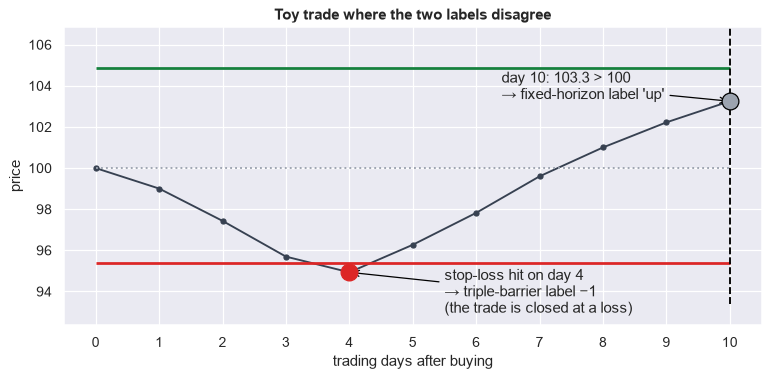

Toy trade: the price drops through the stop-loss on day 4 and is back above 100 by day 10. The fixed-horizon label says "up", but a trader with a stop-loss already sold at a loss.

In [ ]:
stocks = stocks.sort_values(["ticker", "date"])
stocks["fixed_sign"] = stocks.groupby("ticker")["close"].transform(lambda c: np.sign(np.log(c.shift(-HORIZON) / c)))
compare = labels.merge(stocks[["date", "ticker", "fixed_sign"]], on=["date", "ticker"])
crosstab = pd.crosstab(compare.label.map(CLASSES), compare.fixed_sign.map({-1: "lower after H", 0: "equal", 1: "higher after H"}),
                       normalize="index").mul(100)
stopped_but_up = ((compare.label == -1) & (compare.fixed_sign == 1)).mean() * 100

In [ ]:
print(f"events stopped out first but higher after {HORIZON} days: {stopped_but_up:.1f} % of all events")
crosstab.round(1)

**Answer:** they disagree often enough to matter.
- 13 % of the stop-loss trades **still** ended higher after 10 days (3.7 % of all events) → with a stop-loss, these lost money
- 9 % of take-profit trades ended lower after 10 days
- Time-outs split 57 / 42 between higher and lower → a fixed-horizon label turns small, noisy moves into confident up/down labels

Triple-barrier labels describe what actually happens to a trade.

# [8/10] Overlapping labels and sample uniqueness

**Aim** → stop overlapping trades from counting as if they were independent.

**The problem** → a trade starting today and one starting tomorrow share up to 9 of the same future days, so their labels are **not independent**. Counting them as separate samples overstates how much I know and makes cross-validation look too good.

**Uniqueness in one line** → how much of its holding period an event has to itself: 1 = alone, small = shared with many other events.

**How it works** (per stock)
1. **Concurrency** → for each day, count how many events are open on it
2. **Share of a day** → an event owns $1/c_t$ of a day that $c_t$ events share
3. **Uniqueness** → average that share over the event's days
4. **Sample weight** → use uniqueness as the weight in training, so overlapping events share one vote instead of each getting a full one

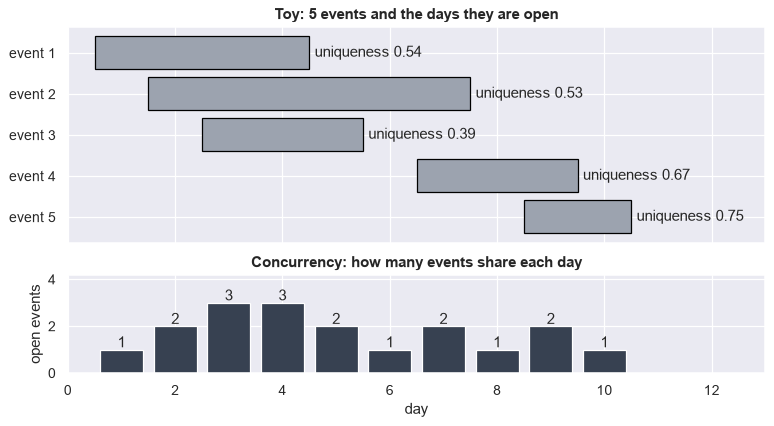

$$\bar u_i = \frac{1}{|T_i|}\sum_{t \in T_i} \frac{1}{c_t}$$
- $T_i$ → the days event $i$ is open, $(t_0, t_1]$; $|T_i|$ → how many days that is
- $c_t$ → **concurrency**: events open on day $t$ (step 1)
- $\bar u_i$ → **average uniqueness**: 1 = no overlap, $\frac{1}{H}$ = completely overlapped
- In short → if 3 trades share a day, each gets a third of it; an event's weight is its average share. Toy event 1 above is open on days with 1, 2, 3 and 3 events → (1 + 1/2 + 1/3 + 1/3) / 4 = 0.54

In [ ]:
u_check = average_uniqueness(lab_ex.index, lab_ex["t1"], c_ex.index)
uniq_summary = labels.groupby("ticker").uniqueness.mean().sort_values()
effective_n = labels.uniqueness.sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.histplot(labels.uniqueness, bins=60, color=PRICE_COLOR, ax=axes[0])
axes[0].set(title="Average uniqueness of events", xlabel="uniqueness")
sns.boxplot(data=labels, x=labels.label.map(CLASSES), y="uniqueness", order=list(CLASSES.values()),
            palette={v: LABEL_COLORS[k] for k, v in CLASSES.items()}, hue=labels.label.map(CLASSES), legend=False, ax=axes[1])
axes[1].set(title="Uniqueness by label", xlabel="")
savefig(fig, "02_uniqueness")
plt.close(fig)

In [ ]:
print(f"events: {len(labels):,}  |  effective number of independent events (sum of uniqueness): {effective_n:,.0f}")
labels.groupby(labels.label.map(CLASSES)).uniqueness.mean().round(3)

In [ ]:
fig

**Answer:** the average event is only about 15 % unique: the 53,592 labelled events carry the information of roughly 8,300 independent trades.
- Stop-loss and take-profit events end early and overlap less → they get more weight than time-outs

→ Models are trained with **uniqueness weights**, and validation uses **purging** (Part 3).

# [9/10] CUSUM filter: sampling events instead of every day

**What I'm trying to do** → test whether starting a trade only after a meaningful move gives cleaner, less overlapping events.

**CUSUM filter in one line** → keep adding up daily returns, and start an event only when the running total has moved more than one daily volatility away from zero.

**How it works**
1. Keep two running totals: one for ups ($S^+$), one for downs ($S^-$)
2. Add each new return; if a total crosses back over 0 it is set to 0
3. When $S^+ > h_t$ or $S^- < -h_t$ → start an event and reset both totals
4. Here $h_t = \sigma_t$, today's daily volatility

$$S^+_t = \max(0, S^+_{t-1} + r_t) \qquad S^-_t = \min(0, S^-_{t-1} + r_t)$$
- $r_t$ → today's log return
- $S^+_t$, $S^-_t$ → running totals of ups and downs since the last event
- $h_t$ → threshold, here $\sigma_t$
- In short → small wiggles are ignored; an event fires only after the price has really moved about one typical day's worth in one direction

The real picture with the CUSUM events on `AAPL` comes after the next cell.

In [ ]:
events = cusum_filter(c_ex, v_ex * CUSUM_VOL_MULT)
cusum_labels = lab_ex.loc[lab_ex.index.intersection(events)]
cusum_compare = pd.DataFrame({
    "every day": lab_ex.label.map(CLASSES).value_counts(normalize=True) * 100,
    "CUSUM events": cusum_labels.label.map(CLASSES).value_counts(normalize=True) * 100,
}).loc[list(CLASSES.values())]
cusum_uniq = average_uniqueness(cusum_labels.index, cusum_labels["t1"], c_ex.index)

window = c_ex.loc["2023-01-01":"2023-06-30"]
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.plot(window.index, window.values, color=PRICE_COLOR)
ev = events[(events >= window.index[0]) & (events <= window.index[-1])]
ax.scatter(ev, c_ex.loc[ev], color="#dc2626", s=25, zorder=5, label="CUSUM event")
ax.set(title=f"{EXAMPLE}: CUSUM events, first half of 2023")
ax.legend()
savefig(fig, "02_cusum")
plt.close(fig)

In [ ]:
print(f"{EXAMPLE}: {len(lab_ex):,} daily events -> {len(cusum_labels):,} CUSUM events; "
      f"mean uniqueness {lab_ex.index.map(u_check).to_series().mean():.3f} -> {cusum_uniq.mean():.3f}")
cusum_compare.round(1)

In [ ]:
fig

**Answer:** for `AAPL`, CUSUM keeps 1,672 of 4,211 events, raises mean uniqueness from 0.16 to 0.39, and leaves the label mix almost unchanged.

For the deep-learning models I still keep **every day** (more training samples) and handle overlap with uniqueness weights instead. CUSUM stays as an option.

# [10/10] Summary

**Aim** → save the labels and list the choices I made.

In [ ]:
save_processed(labels, "labels")
labels[["label", "uniqueness", "days_held"]].describe().round(3)

| Choice | Value | Reason |
|---|---|---|
| Volatility | EWM std of daily log returns, span 20 | adapts to calm and turbulent periods |
| Barriers | $\pm 0.75\,\sigma\sqrt{10}$ | about one third per class |
| Vertical barrier | 10 trading days | two trading weeks |
| Events | every stock-day | more samples for the sequence models |
| Overlap | uniqueness sample weights + purging | labels share future days |

Labels are saved to `data/processed/labels.parquet`.

# Part [3/5] Features & Purged Split

My first version fed raw (scaled) prices to the networks. Here every feature is a return, ratio or oscillator, built from data up to day $t$ only, and no event's outcome may overlap the next data split.

**Outlines**
1. Load prices & labels
2. Fractional differentiation
3. Feature catalogue
4. Build features
5. Which features relate to the label?
6. Purged time split
7. Save dataset
8. Summary

In [ ]:
EXAMPLE = "AAPL"
FFD_THRESHOLD = 1e-3
ADF_ALPHA = 0.05
SPLIT_COLORS = {"train": "#4b5563", "valid": "#9ca3af", "test": "#dc2626", "purged": "black"}

set_style()

# [1/8] Load prices & labels

**Aim** → load the prices and the labels from Part 2.

In [ ]:
prices = download_prices()
labels = load_processed("labels")
market = prices[prices.ticker == MARKET].set_index("date")

In [ ]:
print(f"prices: {prices.shape} | labels: {labels.shape}")

# [2/8] Fractional differentiation

**Aim** → make prices stationary while keeping as much of their memory as possible.

**The problem** → prices are non-stationary (Part 1). Returns are stationary but forget the price level completely (a return is a first difference, $d = 1$).

**Fractional differentiation in one line** → take only "part" of a difference: today's price minus a fading mix of past prices, where $d$ between 0 and 1 says how much to subtract.

**How it works**
1. Pick $d$: $d = 0$ → the price itself, $d = 1$ → plain returns
2. Turn $d$ into weights $w_k$ for today and each past day; for $0 < d < 1$ they fade slowly instead of stopping after one day
3. New value = weighted sum of today's and past log prices; stop once the weights get smaller than $10^{-3}$
4. Try $d$ = 0, 0.05, 0.10, ..., 1 and keep the smallest $d$ that passes the ADF test (p < 0.05), on the **training period only**, so the choice doesn't peek at the future

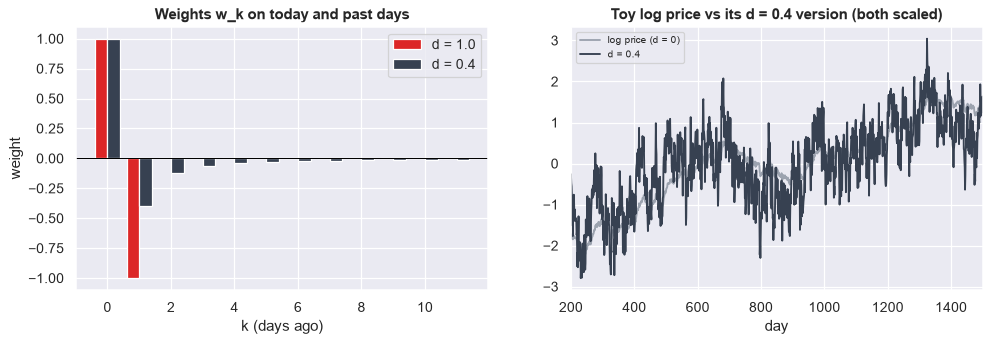

Left: the weights. With $d = 1$ it's just "today minus yesterday"; with $d = 0.4$ a long tail of small negative weights keeps some memory. Right: a toy random walk next to its $d = 0.4$ version.

$$\tilde{x}_t = \sum_{k=0}^{K} w_k\, x_{t-k}, \qquad w_0 = 1,\quad w_k = -w_{k-1}\,\frac{d - k + 1}{k}$$
- $x_{t-k}$ → log price $k$ days ago
- $w_k$ → weight of that day (step 2), cut off when $|w_k| < 10^{-3}$
- $d$ → how much differencing: 0 = none, 1 = full
- $\tilde{x}_t$ → the new stationary feature `ffd_close`
- In short → today's price minus a fading memory of past prices. A small $d$ subtracts only a little, so the series still looks like the price but no longer wanders off

**Question:** what is the smallest $d$ that makes each stock's log price stationary (ADF p < 0.05)?

In [ ]:
d_rows, d_tables = [], {}
for t in TICKERS:
    lp = np.log(prices[(prices.ticker == t) & (prices.date < VALID_START)].set_index("date")["close"])
    d, table = min_d_stationary(lp, threshold=FFD_THRESHOLD, alpha=ADF_ALPHA)
    d_tables[t] = table
    corr = table.loc[table.d == d, "corr_with_price"].iloc[0]
    d_rows.append({"ticker": t, "min_d": d, "corr_with_log_price": corr})
d_choice = pd.DataFrame(d_rows).set_index("ticker")

tab = d_tables[EXAMPLE]
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.plot(tab.d, tab.adf_p, marker="o", color=PRICE_COLOR, label="ADF p-value")
ax1.axhline(ADF_ALPHA, color=PRICE_COLOR, ls="--", lw=1)
ax2 = ax1.twinx()
ax2.plot(tab.d, tab.corr_with_price, marker="s", color="#dc2626", label="correlation with log price")
ax2.grid(False)
ax1.set(xlabel="d", ylabel="ADF p-value", title=f"{EXAMPLE}: stationarity vs memory as d grows")
ax2.set_ylabel("correlation with log price")
fig.legend(loc="center right", bbox_to_anchor=(0.88, 0.5))
savefig(fig, "03_frac_diff")
plt.close(fig)

In [ ]:
d_choice.round(3)

In [ ]:
fig

**Answer:** 13 of the 14 stocks become stationary at $d$ between 0.30 and 0.45, far below $d = 1$, and the result still keeps a 0.92–0.99 correlation with the original log price.
- `IBM` needs $d = 0$: its log price was already stationary over the training years (it moved sideways)
- Returns ($d = 1$) would have thrown that memory away

Each stock uses its own smallest $d$ for the feature `ffd_close`.

# [3/8] Feature catalogue

**Aim** → describe each day with features that only use the past and don't wander off like prices do.

All features at day $t$ use data up to and including $t$. $C$ = close, $r$ = daily log return.

| Group | Feature | Formula / meaning |
|---|---|---|
| Momentum | `ret_1`, `ret_5`, `ret_10`, `ret_21` | $\ln(C_t / C_{t-k})$ |
| Volatility | `vol_21` | std of $r$ over 21 days |
| | `vol_ratio_5_21` | short / long volatility (is volatility rising?) |
| | `atr_14` | Average True Range / $C_t$, with $TR = \max(H - L, |H - C_{t-1}|, |L - C_{t-1}|)$ |
| | `bb_width` | Bollinger band width $4\sigma_{20} / SMA_{20}$ |
| Oscillators | `rsi_14` | $1 - \frac{1}{1 + RS}$, $RS$ = average gain / average loss (Wilder, 14 days), scaled to [0, 1] |
| | `macd_hist` | $(EMA_{12} - EMA_{26}) - \text{signal}_9$, divided by $C_t$ |
| | `bb_pctb` | position inside the Bollinger bands: $\frac{C - (SMA_{20} - 2\sigma)}{4\sigma}$ |
| Trend | `dist_sma_50`, `dist_sma_200`, `dist_ema_21` | $C_t / MA - 1$ (from the SMA / EMA of my first version) |
| Volume | `volume_z` | z-score of log volume vs its 21-day mean |
| Memory | `ffd_close` | fractionally differenced log price (section 2) |
| Market | `mkt_ret_1`, `mkt_ret_5`, `mkt_vol_21` | the same for `SPY` |
| | `rel_strength_21` | stock 21-day return minus `SPY` 21-day return |
| | `beta_63` | $\frac{\text{Cov}(r, r_{SPY})}{\text{Var}(r_{SPY})}$ over 63 days |

In short → every feature is a % change, a ratio or a 0-to-1 score, so a \$20 stock and a \$500 stock look alike to the model.

# [4/8] Build features

**Aim** → compute the features per stock and join them to the labels. The first ~200 days of each stock are dropped (the 200-day average needs a full window).

In [ ]:
parts = []
for t in TICKERS:
    g = prices[prices.ticker == t].set_index("date")
    f = ticker_features(g, market, d_choice.loc[t, "min_d"])
    f["ticker"] = t
    parts.append(f.reset_index())
features = pd.concat(parts, ignore_index=True)
dataset = labels.merge(features, on=["date", "ticker"], how="inner").dropna(subset=FEATURES).reset_index(drop=True)

In [ ]:
print(f"labelled events: {len(labels):,} -> with complete features: {len(dataset):,}")
dataset[FEATURES].describe().T[["mean", "std", "min", "max"]].round(3)

# [5/8] Which features relate to the label?

**What I'm trying to do** → check whether feature values differ between take-profit, time-out and stop-loss events (training period only).

**Kruskal-Wallis in one line** → line up all values from smallest to largest, then check whether one group sits mostly near the top or the bottom.

**How it works**
1. Rank all values together (smallest = 1)
2. Average the ranks within each group (stop-loss, time-out, take-profit)
3. Averages far apart → big $H$ → the feature differs between groups. It works on ranks, so it doesn't need a bell curve (non-parametric)
4. Turn $H$ into an effect size $\eta^2_H$, because with tens of thousands of rows even tiny differences come out "significant"

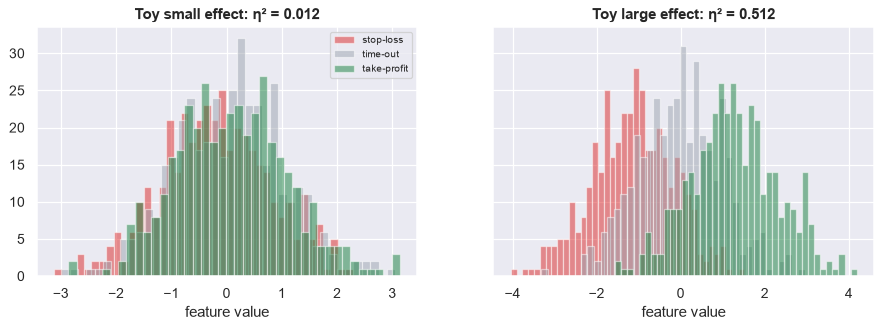

$$\eta^2_H = \frac{H - k + 1}{n - k}$$
- $H$ → Kruskal-Wallis statistic (step 3); $H_0$ → the three groups have the same distribution
- $k = 3$ → number of groups, $n$ → number of rows
- $\eta^2_H$ → **effect size**: 0.01 small, 0.06 medium, 0.14 large
- In short → how much of the spread in ranks the label explains. Near 0 → the three groups overlap almost completely, like the toy on the left

In [ ]:
train_part = dataset[dataset.date < VALID_START]
rows = []
for f in FEATURES:
    groups = [train_part.loc[train_part.label == k, f] for k in CLASSES]
    h, p = stats.kruskal(*groups)
    rows.append({"feature": f, "H": h, "p_value": p, "eta2": (h - 3 + 1) / (len(train_part) - 3),
                 **{f"median_{CLASSES[k]}": g.median() for k, g in zip(CLASSES, groups)}})
kruskal = pd.DataFrame(rows).sort_values("eta2", ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
s = kruskal.set_index("feature")["eta2"].sort_values()
ax.barh(s.index, s.values, color=PRICE_COLOR)
ax.set(title="Kruskal-Wallis effect size per feature (train)", xlabel="eta squared")
savefig(fig, "03_feature_effects")
plt.close(fig)

In [ ]:
kruskal.round(4)

In [ ]:
fig

**Answer:** every effect is **small**. The largest $\eta^2$ is 0.037 for `vol_21`, then 0.026 for `bb_width` and 0.011 for `atr_14`.
- The strongest features are about **volatility**: they mainly separate time-outs from barrier touches (the barrier width itself is volatility-based)
- Momentum and oscillator features barely differ between take-profit and stop-loss

Same as Part 1: volatility is somewhat predictable, direction much less. I expect modest model performance, the honest baseline for a hard problem.

# [6/8] Purged time split

**Aim** → split by time (train < 2022, valid 2022–2023, test 2024 onwards) without letting any label peek into the next period.

**Purging in one line** → remove events whose label is decided with prices from the next period.

**How it works**
1. Give each event to a split by its start date $t_0$
2. Look at its label end $t_1$
3. If $t_1$ falls in the next split → remove the event ("purged")

Example → an event starting on 2021-12-28 with $t_1$ = 2022-01-07 is labelled with January 2022 prices, which belong to the validation period. Keeping it in training leaks validation information into the model.

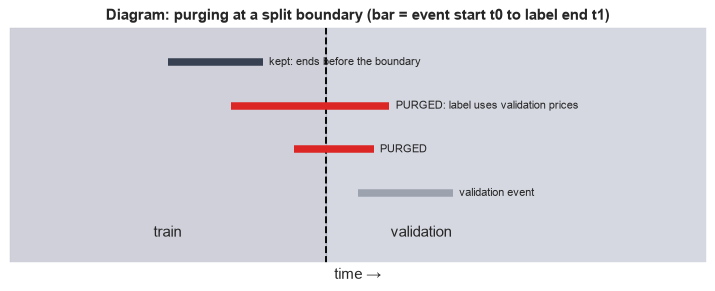

In [ ]:
dataset["split"] = assign_split(dataset, VALID_START, TEST_START)
split_summary = dataset.groupby("split").agg(events=("label", "size"), start=("date", "min"), end=("date", "max"),
                                             take_profit=("label", lambda s: (s == 1).mean()),
                                             stop_loss=("label", lambda s: (s == -1).mean()),
                                             mean_uniqueness=("uniqueness", "mean"))
split_summary = split_summary.loc[["train", "purged", "valid", "test"]]

counts = dataset.groupby([dataset.date.dt.to_period("M"), "split"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(14, 3.8))
bottom = np.zeros(len(counts))
for s_name, c in SPLIT_COLORS.items():
    if s_name in counts:
        ax.bar(counts.index.to_timestamp(), counts[s_name], bottom=bottom, width=25, color=c, label=s_name)
        bottom += counts[s_name].to_numpy()
ax.set(title="Events per month by split", ylabel="events")
ax.legend(loc="upper left")
savefig(fig, "03_split")
plt.close(fig)

In [ ]:
split_summary.round(3)

In [ ]:
fig

**Answer:** 244 events are purged, about 9 per stock at each of the two boundaries (most are stop-losses that hadn't finished when the period ended). Without purging they'd let the model see the first days of the next period.

The class mix shifts between periods (take-profit 37.5 % in train vs 34–35 % later), another reason to judge models with macro-F1.

# [7/8] Save dataset

**Aim** → save features and labels for Part 4. Features are saved **unscaled**; scaling is fitted on the training split inside Part 4.

In [ ]:
keep = ["date", "ticker", "label", "t1", "ret", "barrier", "vol", "days_held", "uniqueness", "split"] + FEATURES
save_processed(dataset[keep], "dataset")
save_processed(d_choice.reset_index(), "frac_diff_d")

In [ ]:
print(f"saved {len(dataset):,} rows x {len(keep)} columns")
dataset.split.value_counts()

# [8/8] Summary

**Aim** → wrap up what goes into the models.

- **21 features**: momentum, volatility, oscillators, trend distance, volume, a fractionally differenced price and market context
- Fractional differentiation makes prices stationary at $d$ = 0.30–0.45 (IBM: 0) while keeping memory that returns lose
- Feature–label relationships are **weak** (all small effect sizes); volatility features matter most
- **Purged time split:** train < 2022, valid 2022–2023, test 2024 onwards

# Part [4/5] Modeling

For a hard, noisy target the real question isn't "which model is best" but "is anything better than guessing?". I compare a no-information baseline, logistic regression, LightGBM and the three recurrent networks of my first version (SimpleRNN, LSTM, GRU) on the **validation** period (2022–2023), with uniqueness sample weights.

**Outlines**
1. Load dataset
2. Metrics
3. Scaling & sample weights
4. Baselines: prior & logistic regression
5. LightGBM
6. Purged vs naive cross-validation
7. Sequences for recurrent networks
8. SimpleRNN, LSTM, GRU
9. Benchmark & save predictions
10. Summary

In [ ]:
os.environ["KERAS_BACKEND"] = "torch"

import json
import time
import warnings

warnings.filterwarnings("ignore")

import joblib
import keras
import lightgbm as lgb
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

SEED = RANDOM_STATE
LOOKBACK = 30
EPOCHS = 60
BATCH_SIZE = 256
PATIENCE = 8
UNITS = 64
DROPOUT = 0.3
LEARNING_RATE = 1e-3
CLIP = 5.0
CV_FOLDS = 5
EMBARGO_DAYS = 10
TO_CLASS = {-1: 0, 0: 1, 1: 2}
LGB_PARAMS = dict(objective="multiclass", n_estimators=2000, learning_rate=0.02, num_leaves=15, min_child_samples=200,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1)

set_style()
keras.utils.set_random_seed(SEED)
DEVICE = "GPU " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

# [1/10] Load dataset

**Aim** → load the features and labels from Part 3; purged events are not used.

In [ ]:
data = load_processed("dataset").sort_values(["ticker", "date"]).reset_index(drop=True)
data["y"] = data["label"].map(TO_CLASS)
is_train, is_valid, is_test = (data.split == s for s in ("train", "valid", "test"))

In [ ]:
print(f"Keras {keras.__version__} on {keras.backend.backend()} ({DEVICE})")
data.split.value_counts()

# [2/10] Metrics

**Aim** → pick scores that a lazy model can't fool on a noisy 3-class target.

**1. Macro-F1** → F1 for each class (a balance of precision and recall), then a plain average, so every class counts the same.

$$\text{Macro-F1} = \frac{1}{3}\sum_{c} F1_c, \qquad F1_c = \frac{2 \cdot \text{precision}_c \cdot \text{recall}_c}{\text{precision}_c + \text{recall}_c}$$
- precision$_c$ → of the days I called $c$, the share that really were $c$
- recall$_c$ → of the real $c$ days, the share I caught
- In short → a model that always says one class gets F1 = 0 on the other two, so its macro-F1 stays at most ~0.17

**2. Balanced accuracy** → recall of each class, averaged.

$$\text{Balanced accuracy} = \frac{1}{3}\sum_c \text{recall}_c$$
- In short → 0.333 = random guessing with 3 classes

**3. Log-loss** → punishes the model by how little probability it gave to what really happened. This is also the loss the networks train on (**categorical cross-entropy**).

$$\text{Log-loss} = -\frac{1}{n}\sum_i \sum_c y_{ic} \ln \hat p_{ic}$$
- $y_{ic}$ → 1 if day $i$ really was class $c$, else 0
- $\hat p_{ic}$ → the model's probability for class $c$ on day $i$
- each day is weighted by its uniqueness
- In short → being sure and wrong costs a lot; honest probabilities score best. The **prior** baseline (always predict the training class frequencies) sets the bar to beat

**4. Take-profit precision** → of the days predicted "take-profit", the share that really were. This is what a buy-only strategy needs.

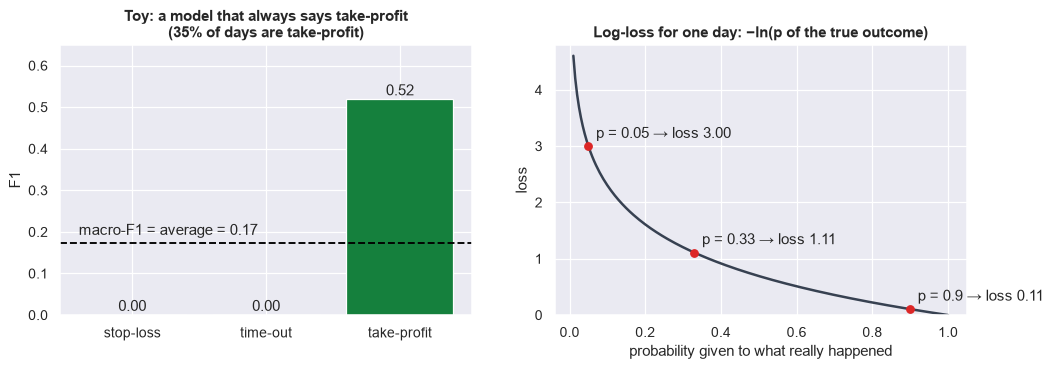

Left: a toy model that always says take-profit (35 % of days) only reaches macro-F1 0.17. Right: the log-loss for one day.

# [3/10] Scaling & sample weights

**Aim** → put all features on the same scale without peeking at validation or test, and let overlapping events share their weight.

**Standardisation in one line** → shift and stretch each feature so that, in the training period, it has average 0 and spread 1.

**How it works**
1. Compute each feature's mean and standard deviation on **training rows only**
2. For every row (train, valid, test): subtract the training mean, divide by the training std
3. Clip to $\pm 5$, so a few extreme days can't dominate

$$z = \frac{x - \mu_{train}}{\sigma_{train}}$$
- $\mu_{train}$, $\sigma_{train}$ → mean and standard deviation of the training rows
- In short → $z$ = how many "typical spreads" a value sits from the training average; $z = 2$ is unusually high, $z = 5$ is the cap

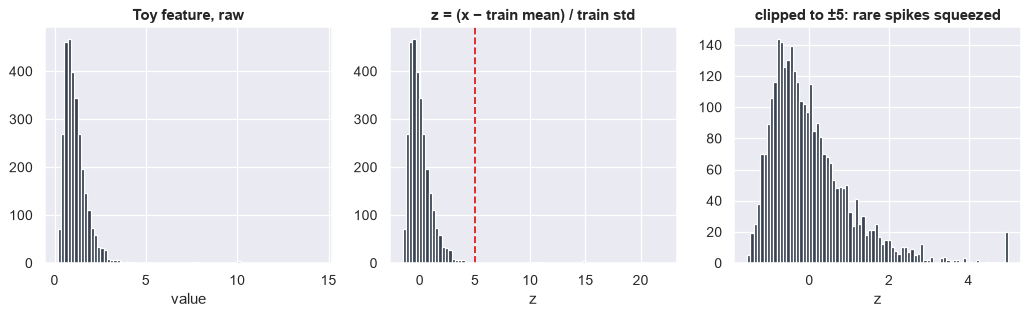

**Sample weight** → event uniqueness (Part 2), rescaled to mean 1 in each split, so overlapping events share weight.

In [ ]:
scaler = StandardScaler().fit(data.loc[is_train, FEATURES])
data[FEATURES] = np.clip(scaler.transform(data[FEATURES]), -CLIP, CLIP).astype(np.float32)
data["w"] = data["uniqueness"] / data.groupby("split")["uniqueness"].transform("mean")

X = {s: data.loc[m, FEATURES] for s, m in [("train", is_train), ("valid", is_valid), ("test", is_test)]}
y = {s: data.loc[m, "y"].to_numpy() for s, m in [("train", is_train), ("valid", is_valid), ("test", is_test)]}
w = {s: data.loc[m, "w"].to_numpy() for s, m in [("train", is_train), ("valid", is_valid), ("test", is_test)]}
y_label = {s: np.array(LABELS)[v] for s, v in y.items()}

In [ ]:
pd.DataFrame({s: [len(y[s]), w[s].mean()] for s in y}, index=["rows", "mean weight"]).round(3)

Helper: every model's validation and test probabilities are stored for the benchmark and for Part 5.

In [ ]:
results, probas = [], {"valid": {}, "test": {}}


def record(name, p_valid, p_test):
    probas["valid"][name], probas["test"][name] = p_valid, p_test
    results.append(score(y_label["valid"], p_valid, name, weights=w["valid"]))


def results_table():
    return pd.DataFrame(results).drop_duplicates("model", keep="last").set_index("model").round(4)

# [4/10] Baselines: prior & logistic regression

**What I'm trying to do** → set the bar: what does knowing nothing score, and what does a simple linear model score?

- **Prior** → predict the training class frequencies for every day (no information at all)
- **Multinomial logistic regression** → a straight-line score per class, turned into probabilities with softmax

**Softmax in one line** → turns 3 raw scores (any numbers) into 3 probabilities that add up to 1; the biggest score gets the biggest share.

**How it works**
1. Each class $c$ gets a score $w_c^\top x$: a weighted sum of the 21 features
2. Raise $e$ to each score → all become positive
3. Divide by their total → they add up to 1

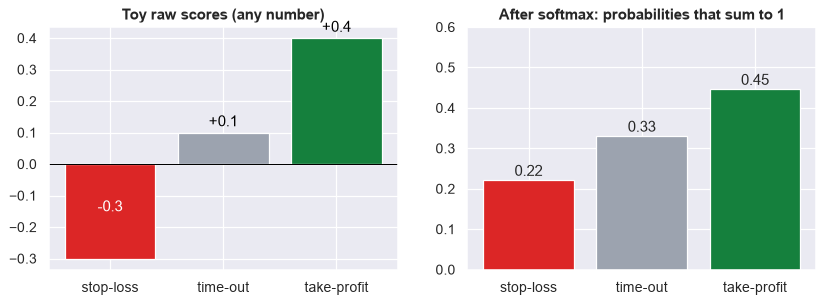

$$P(y = c \mid x) = \frac{e^{w_c^\top x}}{\sum_k e^{w_k^\top x}}$$
- $x$ → the 21 features of one day
- $w_c$ → weights of class $c$, learned in training
- In short → bigger score → bigger probability, and the three always add up to 100 %. Toy scores −0.3, +0.1, +0.4 become 0.22, 0.33, 0.45

The same softmax is the last layer of the recurrent networks.

In [ ]:
prior = np.bincount(y["train"], weights=w["train"], minlength=3) / w["train"].sum()
record("Prior (class frequencies)", np.tile(prior, (len(y["valid"]), 1)), np.tile(prior, (len(y["test"]), 1)))

logreg = LogisticRegression(max_iter=2000, C=0.1).fit(X["train"], y["train"], sample_weight=w["train"])
record("Logistic Regression", logreg.predict_proba(X["valid"]), logreg.predict_proba(X["test"]))

In [ ]:
results_table()

# [5/10] LightGBM

**What I'm trying to do** → see whether a strong non-linear model on the 21 features of the event day (no sequence) beats the baselines.

**Gradient boosting in one line** → build many small decision trees one after another, each one fixing the mistakes the trees before it still make.

**How it works**
1. Start from a simple first guess
2. Look at where the current prediction is still wrong
3. Fit a small tree that pushes the prediction the right way there, and add a small step of it (learning rate 0.02)
4. Repeat; stop when validation log-loss hasn't improved for 100 trees (**early stopping**), which picks the number of trees

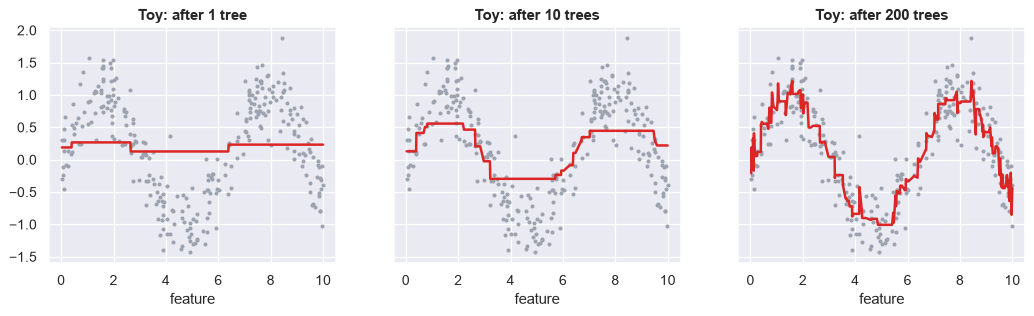

Toy with one feature: after 1 tree the fit is almost flat, after 200 trees it follows the curve.

In [ ]:
lgbm = lgb.LGBMClassifier(**LGB_PARAMS)
lgbm.fit(X["train"], y["train"], sample_weight=w["train"],
         eval_set=[(X["valid"], y["valid"])], eval_sample_weight=[w["valid"]],
         callbacks=[lgb.early_stopping(100, verbose=False)])
record("LightGBM", lgbm.predict_proba(X["valid"]), lgbm.predict_proba(X["test"]))
joblib.dump(lgbm, MODELS_DIR / "lightgbm.joblib")

In [ ]:
print(f"best iteration: {lgbm.best_iteration_}")
results_table()

# [6/10] Purged vs naive cross-validation

**What I'm trying to do** → measure how much ordinary K-fold cross-validation overstates performance when labels overlap in time.

**Cross-validation in one line** → split the training data into 5 parts, train on 4, test on the 5th, and repeat so every part is tested once.

- **Naive K-fold (shuffled)** → days are shuffled before splitting, so a test day's neighbours, which share most of its future prices, sit in the training folds
- **Purged K-fold with embargo** → each fold is one block of time; training events that overlap the test block are removed (**purging**), and so are events starting within 10 days after it (**embargo**, a safety gap)

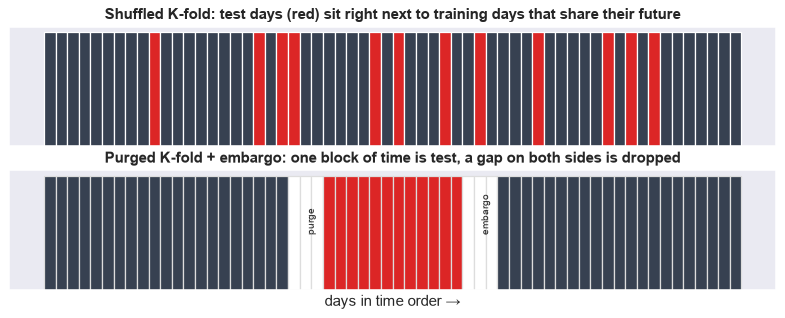

In [ ]:
cv_data = data.loc[is_train].reset_index(drop=True)
cv_model = dict(LGB_PARAMS, n_estimators=300)
cv_rows = []
splitters = {"naive shuffled K-fold": KFold(CV_FOLDS, shuffle=True, random_state=SEED).split(cv_data),
             "purged K-fold + embargo": PurgedKFold(CV_FOLDS, EMBARGO_DAYS).split(cv_data["date"], cv_data["t1"])}
for cv_name, folds in splitters.items():
    for k, (tr, te) in enumerate(folds):
        m = lgb.LGBMClassifier(**cv_model).fit(cv_data.loc[tr, FEATURES], cv_data.loc[tr, "y"],
                                               sample_weight=cv_data.loc[tr, "w"])
        s = score(np.array(LABELS)[cv_data.loc[te, "y"]], m.predict_proba(cv_data.loc[te, FEATURES]), cv_name,
                  weights=cv_data.loc[te, "w"])
        cv_rows.append({**s, "fold": k, "train_rows": len(tr)})
cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby("model")[["macro_f1", "balanced_acc", "log_loss", "train_rows"]].mean()

In [ ]:
cv_summary.round(4)

**Answer:** shuffled K-fold is far too optimistic.

| | Macro-F1 | Log-loss |
|---|---|---|
| Shuffled K-fold | 0.472 | 0.990 |
| Purged K-fold + embargo | 0.394 | 1.068 |
| Truly unseen validation period (LightGBM) | 0.333 | 1.084 |

The gap comes from overlapping neighbours of each test day sitting in the training folds. Purged CV is much closer to reality, though still somewhat optimistic (the market regime also changes between periods). Shuffled K-fold should never be used for this kind of data.

# [7/10] Sequences for recurrent networks

**Aim** → give each event the last 30 days of its stock's features, so the networks can read the recent story: input shape $(n, 30, 21)$.

**Sliding window in one line** → for each event day, cut out the 30 rows of features that end on that day; the next day's window moves one day forward.

**How it works**
1. Sort each stock by date
2. For the event on day $t$, take the features of days $t-29$ to $t$ → a 30 × 21 table
3. Stack all tables → $(n, 30, 21)$: events × days × features
4. A window may reach back into an earlier split; that's past information, available at prediction time, so it's fine

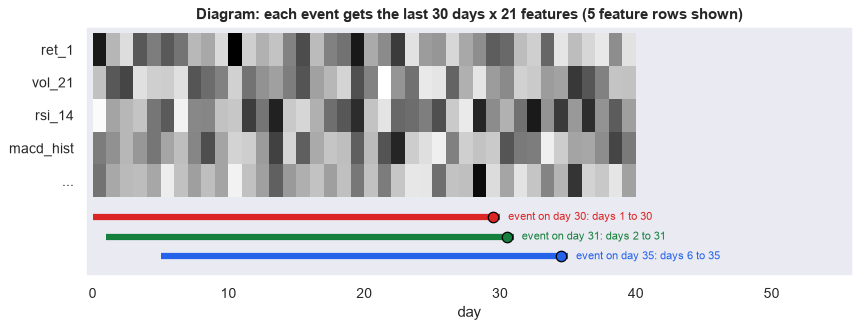

In [ ]:
X_seq_all, row_idx = make_sequences(data, FEATURES, LOOKBACK)
pos = pd.Series(np.arange(len(row_idx)), index=row_idx)
seq = {}
for s, m in [("train", is_train), ("valid", is_valid), ("test", is_test)]:
    rows = data.index[m]
    keep = rows[np.isin(rows, row_idx)]
    seq[s] = (X_seq_all[pos[keep].to_numpy()], data.loc[keep, "y"].to_numpy(), data.loc[keep, "w"].to_numpy(), keep)

In [ ]:
{s: v[0].shape for s, v in seq.items()}

The sequence sets are slightly smaller (each stock's first 29 events have no full window), so for a fair comparison the
non-sequence models are also scored on exactly these rows in the benchmark.

# [8/10] SimpleRNN, LSTM, GRU

**What I'm trying to do** → find out whether reading 30 days in order (recurrent networks) beats looking at one day (logistic regression, LightGBM). I don't know yet if the order carries anything.

**RNN in one line** → a network that reads a sequence one step at a time and carries a small memory (the hidden state $h$) from each step to the next.

It's like watching a friend pick an ice cream every day: day 1 chocolate, day 2 vanilla, day 3 mint, day 4 chocolate again... Each day you update your mental note about their taste (the memory $h$) with today's pick (the input $x_t$), and after 30 days you use that note to guess what comes next. Here each "pick" is one day's 21 features, and the guess is stop-loss / time-out / take-profit.

**How it works**
1. Start with an empty memory $h_0$
2. Day 1: mix the day's features with the memory → new memory $h_1$
3. Repeat for all 30 days, with the same weights every day
4. The last memory $h_{30}$ goes to a dense layer and softmax → 3 probabilities

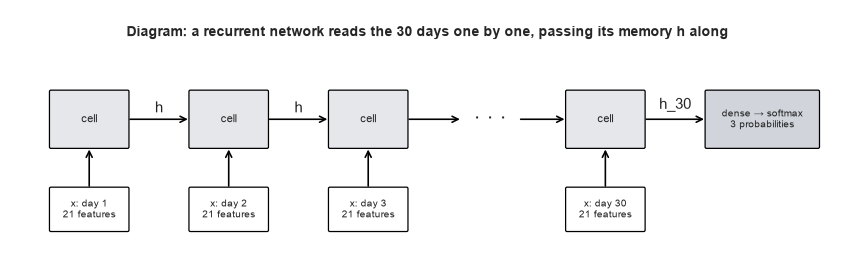

**1. SimpleRNN**

$$h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$$
- $x_t$ → today's 21 features, $h_{t-1}$ → yesterday's memory
- $W_x$, $W_h$, $b$ → learned weights, the same for every day
- $\tanh$ → squashes the result to between −1 and 1
- In short → new memory = a blend of today and the old memory. Old days fade fast, and during training their signal shrinks every step back (the **vanishing gradient** problem on long sequences)

**2. LSTM** → adds a separate long memory belt (the cell state $c_t$) and 3 gates. Each gate is a number from 0 to 1 that works like a tap.

$$c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t \qquad h_t = o_t \odot \tanh(c_t)$$
- $f_t$ → **forget gate**: how much of the old memory to keep
- $i_t$ → **input gate**: how much of today's new candidate $\tilde c_t$ to write
- $o_t$ → **output gate**: how much of the memory to show as $h_t$
- $f_t, i_t, o_t = \sigma(\cdot)$ → each gate is a sigmoid of $x_t$ and $h_{t-1}$, so it lies between 0 and 1
- $\odot$ → multiply element by element
- In short → every day the network decides what to forget, what to write and what to show, so useful old information can survive all 30 days

**3. GRU** → a lighter LSTM: one memory and 2 gates.

$$h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde h_t$$
- $z_t$ → **update gate**: how much of the old memory to replace with the candidate $\tilde h_t$
- $r_t$ → **reset gate**: how much old memory is used to build the candidate
- In short → each day it mixes the old memory and a new idea with one slider $z_t$; fewer parameters than LSTM

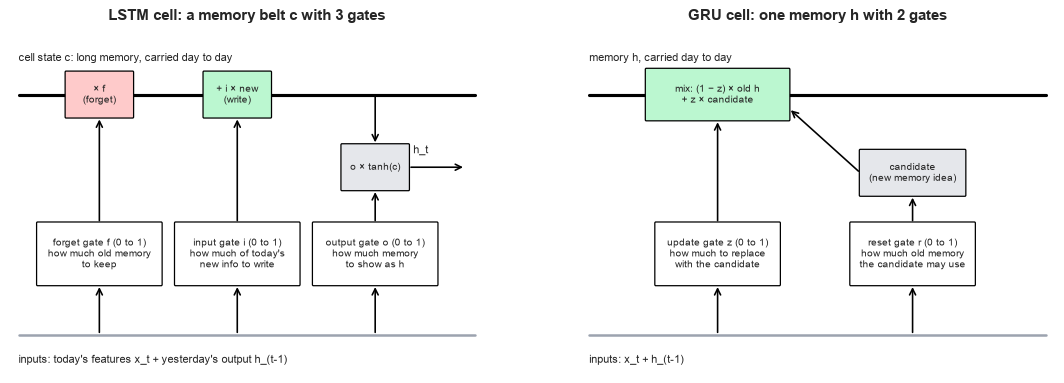

**How I train them** → all three use the same architecture: recurrent layer (64 units) → dropout 0.3 → dense 32 (ReLU) → softmax over 3 classes, trained with Adam on the uniqueness-weighted cross-entropy (log-loss from [2/10]), with early stopping on validation loss.

**Inside the recurrent models** → the same input window and head for all three; only the recurrent cell changes

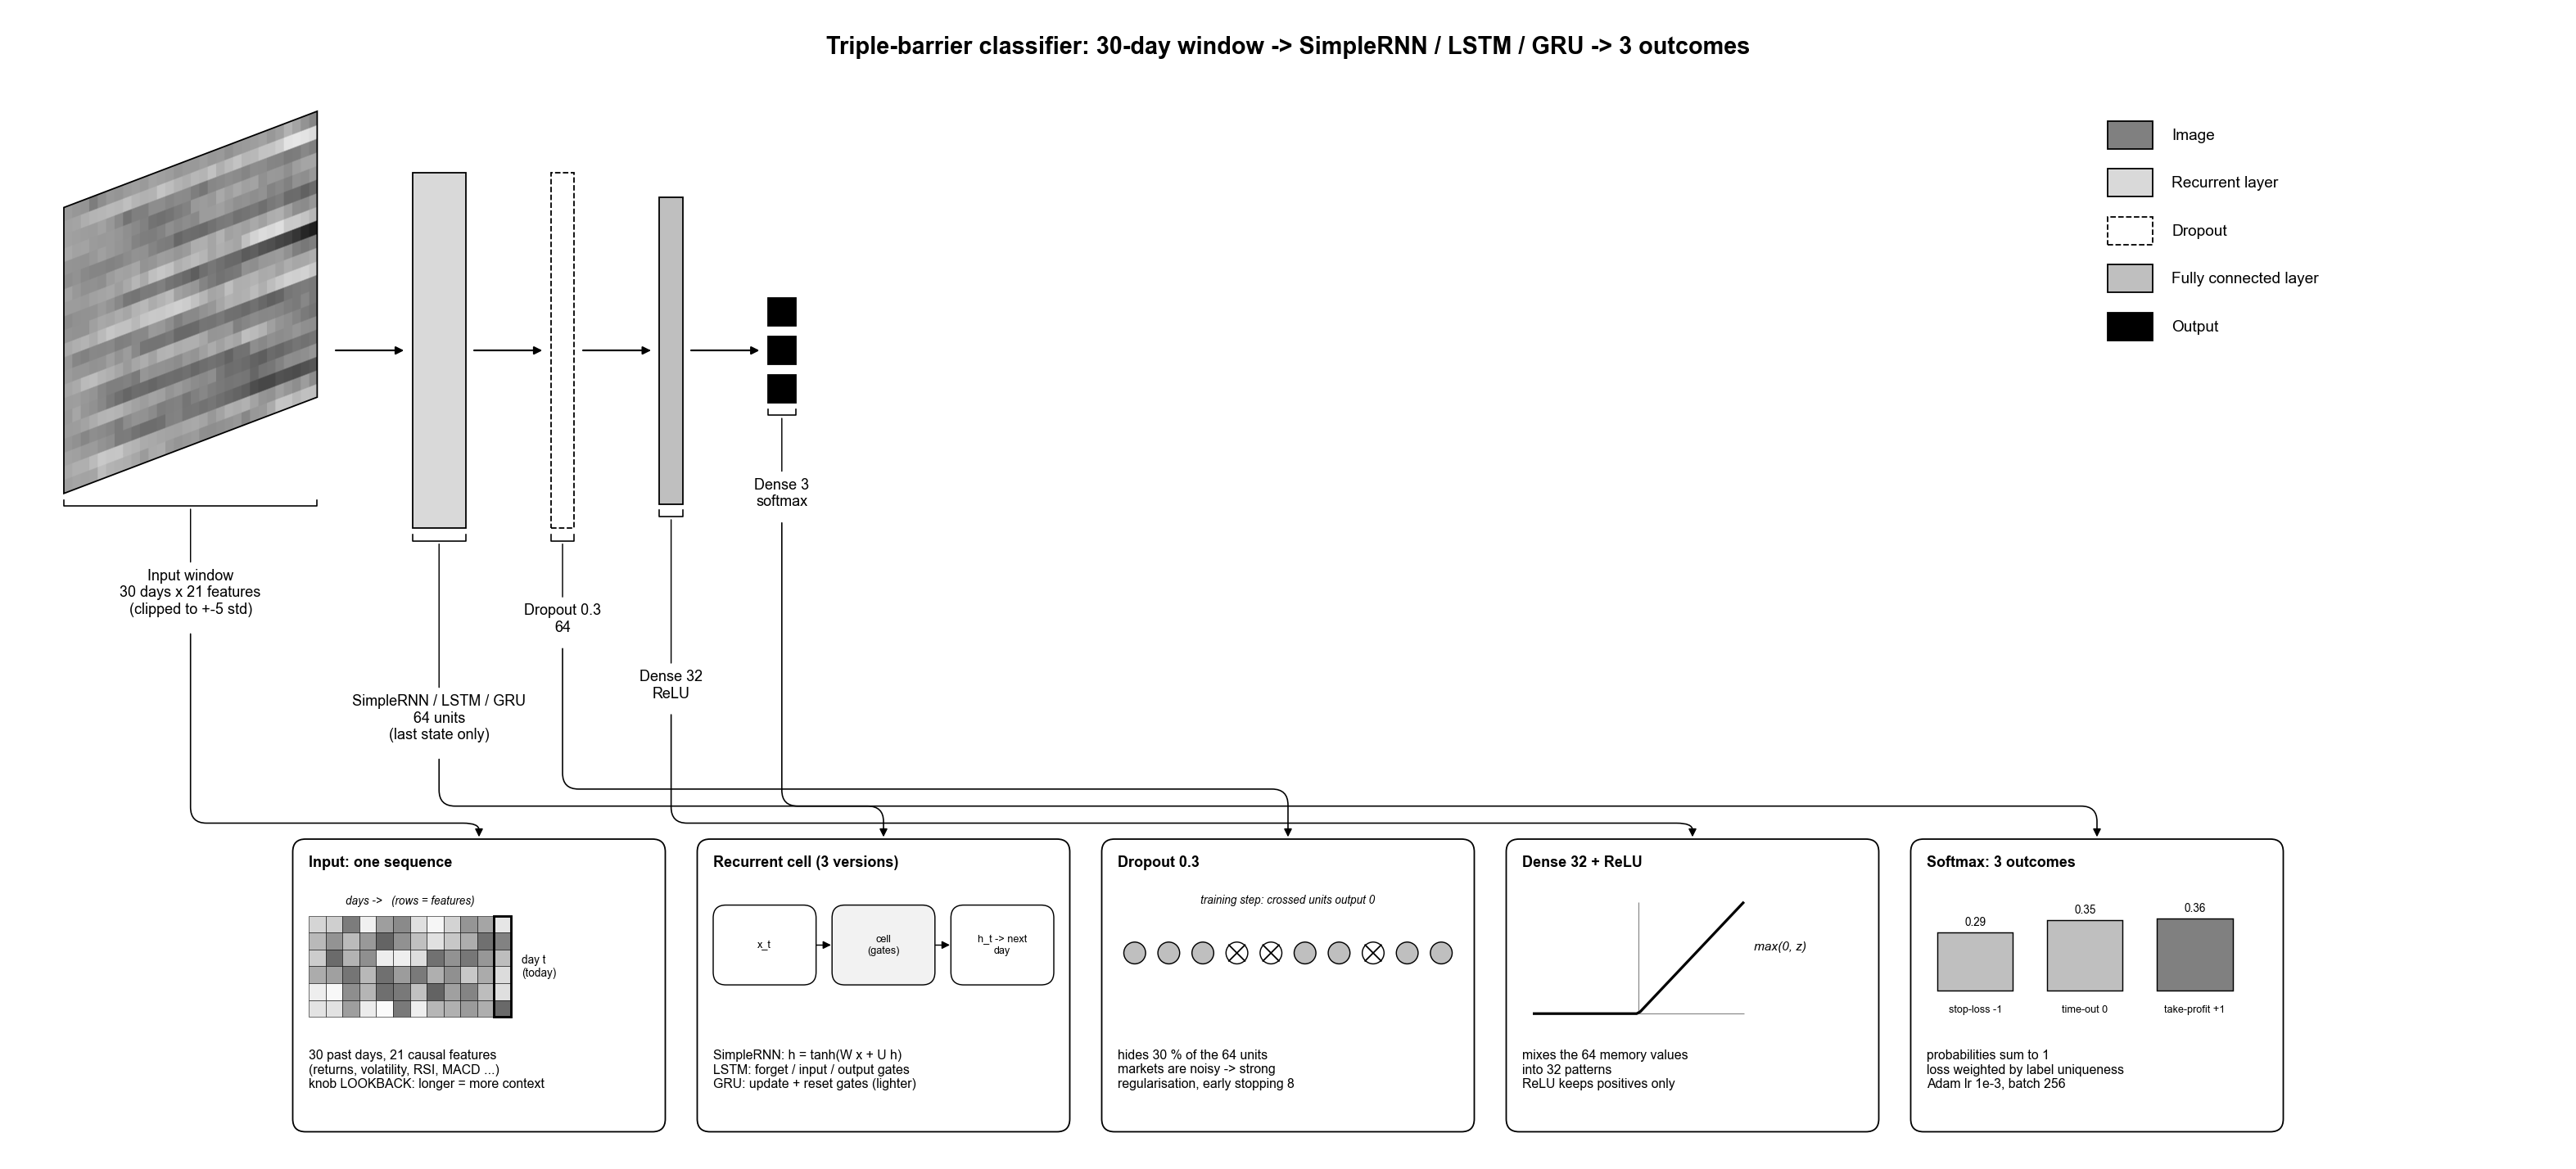

In [ ]:
LAYERS = {"SimpleRNN": keras.layers.SimpleRNN, "LSTM": keras.layers.LSTM, "GRU": keras.layers.GRU}
histories, fit_seconds = {}, {}
Xtr, ytr, wtr, _ = seq["train"]
Xva, yva, wva, _ = seq["valid"]
Xte = seq["test"][0]
for name, layer in LAYERS.items():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        keras.Input((LOOKBACK, len(FEATURES))),
        layer(UNITS),
        keras.layers.Dropout(DROPOUT),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(3, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss="sparse_categorical_crossentropy",
                  weighted_metrics=["accuracy"])
    start = time.time()
    hist = model.fit(Xtr, ytr, sample_weight=wtr, validation_data=(Xva, yva, wva), epochs=EPOCHS, batch_size=BATCH_SIZE,
                     callbacks=[keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True)], verbose=0)
    fit_seconds[name] = time.time() - start
    histories[name] = pd.DataFrame(hist.history)
    model.save(MODELS_DIR / f"{name.lower()}.keras")
    record(name, model.predict(Xva, verbose=0), model.predict(Xte, verbose=0))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h["loss"], color=PRICE_COLOR, label="train")
    ax.plot(h["val_loss"], color="#dc2626", label="validation")
    ax.axvline(h["val_loss"].idxmin(), color="black", ls=":", lw=1)
    ax.set(title=f"{name}: loss per epoch", xlabel="epoch")
    ax.legend()
savefig(fig, "04_training_curves")
plt.close(fig)

In [ ]:
pd.DataFrame({"epochs_run": {k: len(h) for k, h in histories.items()},
              "best_epoch": {k: int(h["val_loss"].idxmin()) + 1 for k, h in histories.items()},
              "fit_seconds": fit_seconds}).round(1)

In [ ]:
fig

**Answer:** validation loss is lowest at epoch 7 (SimpleRNN) and epoch 4 (LSTM, GRU), then rises while training loss keeps falling: the networks start memorising noise (**overfitting**) almost right away. Early stopping restores the best epoch; each network trains in 2–3 minutes on the GPU.

# [9/10] Benchmark & save predictions

**What I'm trying to do** → compare all models fairly, on the **same** validation rows (those with a full 30-day window).

In [ ]:
valid_rows = seq["valid"][3]
test_rows = seq["test"][3]
v_pos = pd.Series(np.arange(is_valid.sum()), index=data.index[is_valid])
t_pos = pd.Series(np.arange(is_test.sum()), index=data.index[is_test])
yv = np.array(LABELS)[data.loc[valid_rows, "y"]]
wv = data.loc[valid_rows, "w"].to_numpy()
bench = []
for name, p in probas["valid"].items():
    p_same = p if name in LAYERS else p[v_pos[valid_rows].to_numpy()]
    bench.append(score(yv, p_same, name, weights=wv))
benchmark = pd.DataFrame(bench).set_index("model").sort_values("log_loss")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
b = benchmark.sort_values("macro_f1")
axes[0].barh(b.index, b["macro_f1"], color=PRICE_COLOR)
axes[0].axvline(1 / 3, color="black", ls=":", lw=1)
axes[0].set(title="Validation macro-F1", xlim=(0, max(0.5, b["macro_f1"].max() * 1.15)))
b = benchmark.sort_values("log_loss", ascending=False)
axes[1].barh(b.index, b["log_loss"], color=["#dc2626" if i.startswith("Prior") else PRICE_COLOR for i in b.index])
axes[1].set(title="Validation log-loss (lower is better; red = prior baseline)",
            xlim=(b["log_loss"].min() * 0.97, b["log_loss"].max() * 1.02))
savefig(fig, "04_benchmark")
plt.close(fig)

out = []
for split_name, rows, posmap in [("valid", valid_rows, v_pos), ("test", test_rows, t_pos)]:
    base = data.loc[rows, ["date", "ticker", "label", "t1", "ret", "uniqueness"]].reset_index(drop=True)
    for name, p in probas[split_name].items():
        p_same = p if name in LAYERS else p[posmap[rows].to_numpy()]
        for c, lab in enumerate(LABELS):
            base[f"{name}|p{lab:+d}"] = p_same[:, c]
    base["split"] = split_name
    out.append(base)
save_processed(pd.concat(out, ignore_index=True), "predictions")
benchmark.to_csv(REPORTS_DIR / "validation_benchmark.csv")
json.dump({"features": FEATURES, "lookback": LOOKBACK, "scaler_mean": scaler.mean_.tolist(),
           "scaler_scale": scaler.scale_.tolist(), "clip": CLIP}, open(REPORTS_DIR / "preprocessing.json", "w"), indent=2)

In [ ]:
benchmark

In [ ]:
fig

**Answer:** every model beats the prior baseline, but only by a little.
- **SimpleRNN** has the best log-loss (1.080 vs 1.100 for the prior) and balanced accuracy (0.414 vs 0.333), with take-profit precision 0.41 against a base rate of 0.35
- LightGBM (1.084) and GRU (1.087) follow; the LSTM is the weakest learned model on log-loss (1.094)
- The recurrent networks reach a higher macro-F1 (0.36–0.37 vs 0.33) partly because they predict stop-loss more often (SimpleRNN 5 %, GRU 7 %, LSTM 18 % of validation days vs 2–3 % for logistic regression and LightGBM). All models mostly predict take-profit (51–59 %) or time-out

The differences between models are small next to the gap to the prior, and come from a single two-year period. Part 5 checks whether the edge survives on the test period and in a backtest with costs.

# [10/10] Summary

**Aim** → wrap up the comparison and save the predictions for Part 5.

- Six models compared on the same validation rows, with uniqueness weights and a purged split
- All learned models beat the prior baseline by a small margin; SimpleRNN is best on log-loss (1.080 vs 1.100)
- Purged cross-validation (macro-F1 0.394) is much more honest than shuffled K-fold (0.472)
- Validation and test probabilities of every model are saved to `data/processed/predictions.parquet` for Part 5

# Part [5/5] Evaluation & Backtest

Scores a little above chance can still be worthless (or useful) once costs, overlapping trades and the market's own trend come in. Here I score every model once on unseen data (2024-01 to 2026-10), backtest a simple buy-only rule against buy-and-hold and random entries, and look inside LightGBM with SHAP.

**Outlines**
1. Load predictions & prices
2. Test-period classification metrics
3. Confusion matrix of the best validation model
4. Are the probabilities meaningful? (take-profit reliability)
5. Trading rule & threshold (validation)
6. Backtest on the test period
7. Is it better than luck? Random-entry benchmark
8. Explainability: SHAP for LightGBM
9. Summary & limitations

In [ ]:
warnings.filterwarnings("ignore")

import shap
from sklearn.metrics import confusion_matrix

MODELS = ["Logistic Regression", "LightGBM", "SimpleRNN", "LSTM", "GRU"]
BEST_VALID_MODEL = "SimpleRNN"
COST_BPS = 10
THRESHOLD_GRID = np.round(np.arange(0.30, 0.66, 0.02), 2)
MIN_TRADES = 50
N_RANDOM = 200
RELIABILITY_BINS = [0, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 1.0]
SHAP_SAMPLE = 3000
STRATEGY_COLORS = {"Buy & hold (same stocks)": "#9ca3af", "Random entries (median)": "black"}

set_style()

# [1/9] Load predictions & prices

**Aim** → load the validation and test probabilities saved in Part 4 (same rows for every model).

In [ ]:
pred = load_processed("predictions")
prices = download_prices()
stock_prices = prices[prices.ticker.isin(TICKERS)]
valid, test = pred[pred.split == "valid"].reset_index(drop=True), pred[pred.split == "test"].reset_index(drop=True)
P = {s: {m: d[[f"{m}|p{l:+d}" for l in LABELS]].to_numpy() for m in MODELS + ["Prior (class frequencies)"]}
     for s, d in [("valid", valid), ("test", test)]}

In [ ]:
print(f"valid: {len(valid):,} events ({valid.date.min().date()} to {valid.date.max().date()}) | "
      f"test: {len(test):,} events ({test.date.min().date()} to {test.date.max().date()})")

# [2/9] Test-period classification metrics

**What I'm trying to do** → see whether any model still beats the prior baseline on 2024–2026 data it has never seen.

In [ ]:
w_test = test["uniqueness"] / test["uniqueness"].mean()
test_metrics = pd.DataFrame([score(test["label"].to_numpy(), P["test"][m], m, weights=w_test)
                             for m in ["Prior (class frequencies)"] + MODELS]).set_index("model")
test_metrics["log_loss_vs_prior"] = test_metrics["log_loss"] - test_metrics.loc["Prior (class frequencies)", "log_loss"]
valid_metrics = pd.read_csv(REPORTS_DIR / "validation_benchmark.csv", index_col=0)
compare = pd.DataFrame({"valid_log_loss": valid_metrics["log_loss"], "test_log_loss": test_metrics["log_loss"],
                        "valid_balanced_acc": valid_metrics["balanced_acc"], "test_balanced_acc": test_metrics["balanced_acc"]})

In [ ]:
test_metrics.sort_values("log_loss").round(4)

In [ ]:
compare.sort_values("test_log_loss").round(4)

**Answer:** yes, by a small margin.
- Test log-loss: SimpleRNN 1.060, GRU 1.064, logistic regression 1.067, LightGBM 1.071, LSTM 1.072, all below the prior's 1.099
- Balanced accuracy 0.40–0.41 vs 0.33 for guessing

The edge is similar to validation, so it's not an artefact of picking the model. SimpleRNN, chosen on validation, is also best on test log-loss, but the gaps between models (≤ 0.012) are much smaller than the gap to the prior.

# [3/9] Confusion matrix of the best validation model

**What I'm trying to do** → see which outcomes the model mixes up.

**Confusion matrix in one line** → a table of true label (rows) vs predicted label (columns). Each row is divided by its total, so a row shows where the real cases of that class ended up; the diagonal = correct.

In [ ]:
pred_best = np.array(LABELS)[P["test"][BEST_VALID_MODEL].argmax(1)]
cm = confusion_matrix(test["label"], pred_best, labels=LABELS, normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(cm, cmap="Greys", vmin=0, vmax=1)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.5 else "black", fontsize=13)
names = [CLASSES[k] for k in LABELS]
ax.set(xticks=range(3), yticks=range(3), xticklabels=names, yticklabels=names, xlabel="predicted", ylabel="true",
       title=f"{BEST_VALID_MODEL}: test confusion matrix")
ax.grid(False)
savefig(fig, "05_confusion")
plt.close(fig)

In [ ]:
pd.Series(pred_best).map(CLASSES).value_counts(normalize=True).round(3).rename("share of test predictions")

In [ ]:
fig

**Answer:** the model can tell **"will the price move enough to hit a barrier?"** much better than **"which way?"**.
- 60 % of time-outs are recognised
- True stop-losses are predicted as take-profit 60 % of the time, about as often as true take-profits (57 %)
- It predicts stop-loss for only 5.5 % of test days

That fits the features: volatility carries most of the signal (Part 3) and direction is close to unpredictable (Part 1).

# [4/9] Are the probabilities meaningful? (take-profit reliability)

**What I'm trying to do** → check that a higher P(take-profit) really means take-profit happens more often.

**Reliability check in one line** → group days by predicted P(take-profit), then compare the average prediction in each group with how often take-profit really happened. A useful model shows an **increasing** observed rate; a perfect one sits on the diagonal.

In [ ]:
rel_rows = []
for m in ["LightGBM", BEST_VALID_MODEL]:
    p_tp = P["test"][m][:, 2]
    g = pd.DataFrame({"p": p_tp, "tp": test["label"].eq(1)}).groupby(pd.cut(p_tp, RELIABILITY_BINS), observed=True)
    r = g.agg(events=("tp", "size"), mean_predicted=("p", "mean"), observed_tp_rate=("tp", "mean")).reset_index()
    r["model"] = m
    rel_rows.append(r)
reliability = pd.concat(rel_rows)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot([0.2, 0.7], [0.2, 0.7], ls="--", c="grey", label="perfect")
for m, c in [("LightGBM", PRICE_COLOR), (BEST_VALID_MODEL, "#dc2626")]:
    r = reliability[(reliability.model == m) & (reliability.events >= 30)]
    ax.plot(r.mean_predicted, r.observed_tp_rate, marker="o", color=c, label=m)
ax.axhline(test["label"].eq(1).mean(), color="black", lw=0.8, ls=":", label="test take-profit rate")
ax.set(xlabel="predicted P(take-profit)", ylabel="observed take-profit rate", title="Take-profit reliability (test)")
ax.legend()
savefig(fig, "05_reliability")
plt.close(fig)

In [ ]:
reliability.round(3)

In [ ]:
fig

**Answer:** partly. The ranking carries information:
- LightGBM: the observed take-profit rate rises from 24 % in the lowest bin to 54 % at 0.50–0.55
- SimpleRNN: from 24 % up to 60 % above 0.60

But SimpleRNN is over-confident in the middle (predicted 0.52, observed 0.40), and LightGBM is slightly over-confident everywhere.

# [5/9] Trading rule & threshold (validation)

**Aim** → turn the probabilities into a simple buy-only rule and fix its threshold on validation, before touching the test period.

**The rule** (long-only = buy only, no short selling)
1. On day $t_0$, if $P(\text{take-profit}) \ge \tau$ and I don't already hold the stock → buy at the close
2. Sell at the close of $t_1$ (take-profit, stop-loss or day 10)
3. One position per stock; capital split equally across the 14 stocks; idle cash earns 0
4. Cost: 10 bp (0.10 %) on entry and on exit
5. $\tau$ is chosen per model to maximise the **validation** Sharpe (at least 50 trades), then frozen for the test period

**Sharpe ratio in one line** → average daily return divided by how bumpy the returns are, scaled to a year: return per unit of risk.

$$\text{Sharpe} = \frac{\bar r}{\sigma_r}\sqrt{252}$$
- $\bar r$ → average daily return, $\sigma_r$ → its standard deviation (no risk-free rate)
- $\sqrt{252}$ → about 252 trading days in a year
- In short → how much I earn for each unit of up-and-down I have to sit through. Higher = smoother gains

**Max drawdown in one line** → the worst fall from a previous peak.

$$\text{max drawdown} = \min_t \left(\frac{E_t}{\max_{s \le t} E_s} - 1\right)$$
- $E_t$ → portfolio value on day $t$, $\max_{s \le t} E_s$ → highest value so far
- In short → the biggest loss I'd have felt if I had bought at the worst possible peak

**CAGR** → compound annual growth rate: the steady yearly growth that would give the same end result.

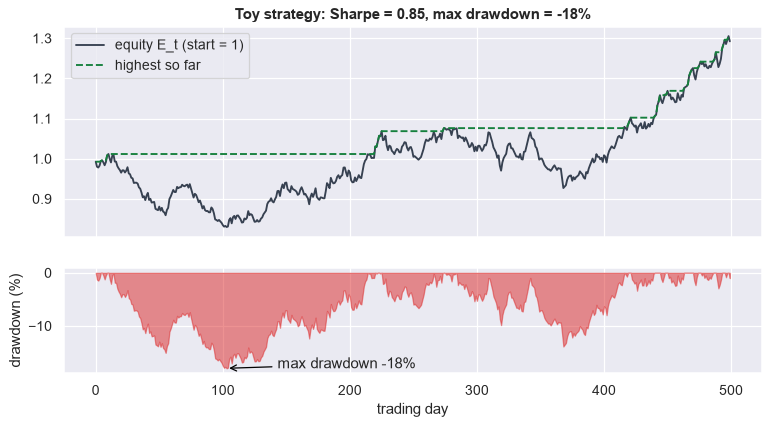

The picture is a toy equity curve, just to show what Sharpe and drawdown measure.

In [ ]:
def portfolio(events, signal, period_prices):
    daily, trades = backtest_long(events, signal, period_prices, COST_BPS)
    simple = (np.exp(daily) - 1).reindex(columns=TICKERS).fillna(0).mean(axis=1)
    return np.log1p(simple), trades


def period_slice(events):
    start, end = events.date.min(), events.t1.max()
    return stock_prices[(stock_prices.date >= start - pd.Timedelta(days=5)) & (stock_prices.date <= end)], start, end


valid_prices, v_start, v_end = period_slice(valid)
tau_rows = []
for m in MODELS:
    p_tp = pd.Series(P["valid"][m][:, 2])
    for tau in THRESHOLD_GRID:
        sig = p_tp >= tau
        if sig.sum() < MIN_TRADES:
            continue
        r, trades = portfolio(valid, sig, valid_prices)
        r = r[(r.index > v_start) & (r.index <= v_end)]
        tau_rows.append({"model": m, "tau": tau, "signals": int(sig.sum()), "trades": len(trades), **performance(r)})
tau_table = pd.DataFrame(tau_rows)
best_tau = tau_table.loc[tau_table.groupby("model")["sharpe"].idxmax()].set_index("model")

In [ ]:
best_tau[["tau", "signals", "trades", "sharpe", "cagr", "max_drawdown"]].round(3)

**Answer:** the best validation thresholds lie between 0.46 and 0.58. Picking $\tau$ by maximising Sharpe over a grid on one two-year period is itself a kind of overfitting, and the test period will show it.

# [6/9] Backtest on the test period

**What I'm trying to do** → with thresholds frozen from validation, see whether the rule beats buying and holding the same 14 stocks.

In [ ]:
test_prices, t_start, t_end = period_slice(test)
close = test_prices.pivot(index="date", columns="ticker", values="close")
bh = np.log1p((close.pct_change()).reindex(columns=TICKERS).mean(axis=1))
bh = bh[(bh.index > t_start) & (bh.index <= t_end)]

curves, perf_rows, trade_stats = {"Buy & hold (same stocks)": bh}, [], []
perf_rows.append({"strategy": "Buy & hold (same stocks)", **performance(bh), "exposure": 1.0, "trades": np.nan})
for m in MODELS:
    sig = pd.Series(P["test"][m][:, 2] >= best_tau.loc[m, "tau"])
    r, trades = portfolio(test, sig, test_prices)
    r = r[(r.index > t_start) & (r.index <= t_end)]
    curves[m] = r
    exposure = (r != 0).mean()
    perf_rows.append({"strategy": m, **performance(r), "exposure": exposure, "trades": len(trades)})
    trade_stats.append({"model": m, "trades": len(trades), "take_profit_share": (trades.label == 1).mean(),
                        "stop_loss_share": (trades.label == -1).mean(), "mean_trade_return_%": trades.ret.mean() * 100})
perf = pd.DataFrame(perf_rows).set_index("strategy")
trade_stats = pd.DataFrame(trade_stats).set_index("model")
base_tp_rate = test.drop_duplicates(["date", "ticker"])["label"].eq(1).mean()

In [ ]:
perf.round(3)

In [ ]:
print(f"take-profit share of ALL test events (base rate): {base_tp_rate:.3f}")
trade_stats.round(3)

**Answer:** no model beats buy-and-hold.

| Test 2024-01 to 2026-10 | Total return | Sharpe | Max drawdown |
|---|---|---|---|
| Buy & hold (same 14 stocks) | 97 % (CAGR 27 %) | 1.06 | −28 % |
| Model rules | 1–21 % | 0.10–0.78 | −3 % to −10 % |

**Why total return isn't a fair comparison** → each stock gets 1/14 of the capital and is held only after a signal, so on average just **5–11 % of the capital is invested** (the `exposure` column counts days with at least one open position, 39–71 %). Sharpe and drawdown ignore how much capital is used, and on Sharpe every rule is still below buy-and-hold (best: LSTM 0.78, logistic regression 0.76, SimpleRNN 0.64 vs 1.06). The small drawdowns mostly reflect the idle cash.

**The good news** → the signals do pick better trades than average: 44–51 % of the rules' trades hit take-profit, against 34 % of all test events.

**The bad news** → the validation-optimal thresholds didn't carry over well (GRU: validation Sharpe 1.54, test 0.10).

# [7/9] Is it better than luck? Random-entry benchmark

**What I'm trying to do** → check whether the best model's Sharpe is more than luck.

**Random-entry benchmark in one line** → trade on random days instead of model signals, with the same number of trades per stock, the same rule and the same costs, 200 times. If the model isn't clearly above most random runs, its signals add nothing beyond being in the market.

**How it works**
1. Count the model's signals per stock
2. Pick that many random days for each stock
3. Run the same backtest → one Sharpe
4. Repeat 200 times → a range of "lucky" Sharpes to compare with

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
ref_model = BEST_VALID_MODEL
ref_sig = pd.Series(P["test"][ref_model][:, 2] >= best_tau.loc[ref_model, "tau"])
per_ticker_n = ref_sig.groupby(test["ticker"]).sum()
random_sharpes, random_curves = [], []
for _ in range(N_RANDOM):
    sig = pd.Series(False, index=test.index)
    for t, n in per_ticker_n.items():
        idx = test.index[test.ticker == t]
        sig[rng.choice(idx, int(n), replace=False)] = True
    r, _ = portfolio(test, sig, test_prices)
    r = r[(r.index > t_start) & (r.index <= t_end)]
    random_sharpes.append(performance(r)["sharpe"])
    random_curves.append(r.cumsum())
random_sharpes = np.array(random_sharpes)
model_sharpe = perf.loc[ref_model, "sharpe"]
percentile = (random_sharpes < model_sharpe).mean() * 100
curves["Random entries (median)"] = pd.concat(random_curves, axis=1).median(axis=1).diff().fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1.6, 1]})
for name, r in curves.items():
    color = STRATEGY_COLORS.get(name)
    lw = 2.5 if name in (ref_model, "Buy & hold (same stocks)") else 1.2
    axes[0].plot(np.exp(r.cumsum()), label=name, color=color, lw=lw)
axes[0].set(title="Growth of $1 on the test period (after costs)", ylabel="equity")
axes[0].legend(fontsize=9)
axes[1].hist(random_sharpes, bins=30, color="#9ca3af")
axes[1].axvline(model_sharpe, color="#dc2626", lw=2.5, label=f"{ref_model}: {model_sharpe:.2f}")
axes[1].set(title=f"Sharpe of {N_RANDOM} random-entry runs", xlabel="Sharpe")
axes[1].legend()
savefig(fig, "05_backtest")
plt.close(fig)

In [ ]:
print(f"{ref_model} Sharpe {model_sharpe:.2f} beats {percentile:.0f} % of random-entry runs "
      f"(random median {np.median(random_sharpes):.2f}, 5-95 % range {np.percentile(random_sharpes, 5):.2f} to "
      f"{np.percentile(random_sharpes, 95):.2f})")

In [ ]:
fig

**Answer:** not convincingly. SimpleRNN's Sharpe of 0.64 beats 79 % of random-entry runs with the same number of trades per stock (random median 0.27). That's better than typical luck, but well inside the random range (5–95 %: −0.51 to 0.92), so this test can't tell the signal from chance.

# [8/9] Explainability: SHAP for LightGBM

**What I'm trying to do** → find which features push the LightGBM model towards **take-profit**.

**SHAP in one line** → split one prediction into a starting value (the average) plus a push from each feature; the pushes add up exactly to the prediction.

**How it works**
1. Start from the model's average output ($\phi_0$)
2. For each feature, measure how much knowing its value moves the prediction, averaged over all orders in which the features could be added
3. Positive push → towards take-profit, negative → away from it
4. Average the size of the pushes over 3,000 test days → feature importance

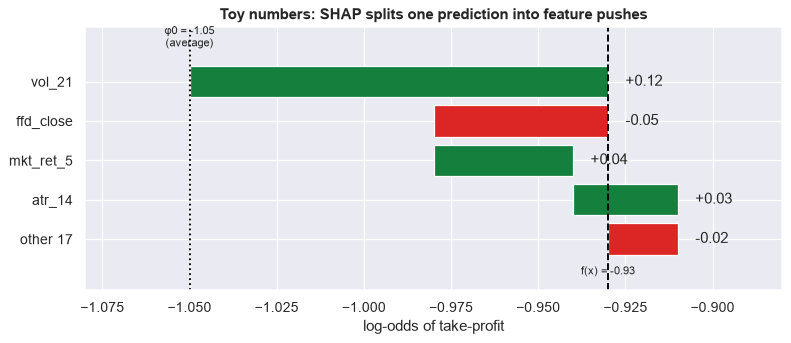

The picture uses toy numbers for one day; the real summary plot comes after the next cell.

$$f(x) = \phi_0 + \sum_j \phi_j$$
- $f(x)$ → the model's output for one day, as log-odds of take-profit (the probability stretched to run from −∞ to +∞)
- $\phi_0$ → average output (step 1)
- $\phi_j$ → push from feature $j$ (step 2)
- In short → prediction = average + pushes; a feature with a big push mattered a lot for that day

In [ ]:
lgbm = joblib.load(MODELS_DIR / "lightgbm.joblib")
dataset = load_processed("dataset")
prep = json.load(open(REPORTS_DIR / "preprocessing.json"))
X_test = dataset[dataset.split == "test"][FEATURES]
X_test = np.clip((X_test - prep["scaler_mean"]) / prep["scaler_scale"], -prep["clip"], prep["clip"]).astype(np.float32)
X_shap = X_test.sample(SHAP_SAMPLE, random_state=RANDOM_STATE)
explanation = shap.TreeExplainer(lgbm)(X_shap)
tp_values = explanation[:, :, 2]
importance = pd.Series(np.abs(tp_values.values).mean(0), index=FEATURES).sort_values(ascending=False)

plt.figure(figsize=(9, 7))
shap.plots.beeswarm(tp_values, max_display=15, show=False, plot_size=None)
plt.title("SHAP values for take-profit (LightGBM, test sample)")
fig_shap = plt.gcf()
savefig(fig_shap, "05_shap_take_profit")
plt.close(fig_shap)

In [ ]:
importance.round(4).head(10)

In [ ]:
fig_shap

**Answer:** `vol_21` dominates by far (mean |SHAP| 0.085, twice the next feature), followed by `ffd_close` (the fractionally differenced price), `mkt_ret_5`, `atr_14` and `vol_ratio_5_21`.

Mostly volatility and market context, very little momentum. Same story as the confusion matrix: the model mainly predicts *how much* a stock will move.

# [9/9] Summary & limitations

**Aim** → save the test results and list what I found and what could break it.

In [ ]:
summary = {
    "test_log_loss": test_metrics["log_loss"].round(4).to_dict(),
    "test_balanced_acc": test_metrics["balanced_acc"].round(4).to_dict(),
    "backtest": perf[["sharpe", "cagr", "max_drawdown", "exposure"]].round(4).to_dict(orient="index"),
    "random_entry_percentile_of_" + ref_model: round(float(percentile), 1),
    "thresholds": best_tau["tau"].to_dict(),
}
json.dump(summary, open(REPORTS_DIR / "test_results.json", "w"), indent=2, default=float)

In [ ]:
pd.Series({k: v for k, v in summary.items() if not isinstance(v, dict)})

**Findings**
- Triple-barrier outcomes are predictable **slightly** better than chance on unseen 2024–2026 data (log-loss 1.060 vs 1.099,
  balanced accuracy 0.41 vs 0.33), and the edge held from validation to test.
- The models mainly predict **whether** a stock will move enough to hit a barrier, not the direction.
- The recurrent networks were not clearly better than logistic regression or LightGBM.
- As a long-only rule, no model beats buy-and-hold of the same stocks, and the best model's Sharpe sits inside the range of
  random entries. There is **no tradable edge** here, which is the expected result for liquid large-cap stocks with public data.

**Limitations**
- **Selection bias:** the 14 stocks were chosen in hindsight and mostly rose; buy-and-hold of them is an unusually strong benchmark.
- **One test period** (2024–2026, a strong market). Results could differ in other regimes; walk-forward retraining would test this.
- **Simple execution:** trades at the close, 10 bp per side, no slippage model, no shorting, no position sizing by probability.
- **Small effects:** feature–label relationships are weak (Part 3), so differences between models are within noise.